<a href="https://colab.research.google.com/github/SeratAftab/Domain-Classification/blob/main/Domain_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Setup and Loading dataset

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

DATA_PATH = '/content/drive/MyDrive/Domain Classification/Copy of HealthCareMagic-100k.xlsx'

df = pd.read_excel(DATA_PATH)

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
df.head()

Mounted at /content/drive
Shape: (100000, 3)

Columns: ['instruction', 'input', 'output']


,instruction,input,output
0,"If you are a doctor, please answer the medical...",I woke up this morning feeling the whole room ...,"Hi, Thank you for posting your query. The most..."
1,"If you are a doctor, please answer the medical...",My baby has been pooing 5-6 times a day for a ...,Hi... Thank you for consulting in Chat Doctor....
2,"If you are a doctor, please answer the medical...","Hello, My husband is taking Oxycodone due to a...","Hello, and I hope I can help you today.First, ..."
3,"If you are a doctor, please answer the medical...",lump under left nipple and stomach pain (male)...,HI. You have two different problems. The lump ...
4,"If you are a doctor, please answer the medical...",I have a 5 month old baby who is very congeste...,Thank you for using Chat Doctor. I would sugge...


# Data Check

In [ ]:

print("Missing values:\n", df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate 'input' entries:", df['input'].duplicated().sum())

df['input_word_count'] = df['input'].astype(str).apply(lambda x: len(x.split()))

print("\nInput word count stats:")
print(df['input_word_count'].describe())

df['output_word_count'] = df['output'].astype(str).apply(lambda x: len(x.split()))
print("\nOutput word count stats:")
print(df['output_word_count'].describe())

for i in range(3):
    print(f"\n--- Sample {i} ---")
    print("INPUT:", df['input'].iloc[i][:200])
    print("OUTPUT:", df['output'].iloc[i][:200])

Missing values:
 instruction    0
input          8
output         0
dtype: int64

Duplicate rows: 0
Duplicate 'input' entries: 140

Input word count stats:
count    100000.000000
mean         81.135020
std          47.497904
min           1.000000
25%          56.000000
50%          68.000000
75%          92.000000
max        2218.000000
Name: input_word_count, dtype: float64

Output word count stats:
count    100000.000000
mean        102.021650
std          41.330179
min           1.000000
25%          78.000000
50%          95.000000
75%         119.000000
max         591.000000
Name: output_word_count, dtype: float64

--- Sample 0 ---
INPUT: I woke up this morning feeling the whole room is spinning when i was sitting down. I went to the bathroom walking unsteadily, as i tried to focus i feel nauseous. I try to vomit but it wont come out..
OUTPUT: Hi, Thank you for posting your query. The most likely cause for your symptoms is benign paroxysmal positional vertigo (BPPV), a type of p

In [ ]:
df = df.dropna(subset=['input']).reset_index(drop=True)
print("New shape:", df.shape)

New shape: (99992, 5)


# Domain Catagories (Zero Shot Labeling)

In [ ]:

from transformers import pipeline
import torch

DOMAIN_LABELS = [
    "Respiratory",
    "Cardiovascular",
    "Gastrointestinal",
    "Musculoskeletal",
    "Neurological",
    "Dermatological",
    "Genitourinary/Reproductive"
]

device = 0 if torch.cuda.is_available() else -1
classifier = pipeline(
    "zero-shot-classification",
    model="facebook/bart-large-mnli",
    device=device
)

def classify_domain(text, labels=DOMAIN_LABELS):
    result = classifier(text, candidate_labels=labels, multi_label=False)
    return result['labels'][0], result['scores'][0]

sample_texts = df['input'].iloc[:5].tolist()
for text in sample_texts:
    label, score = classify_domain(text)
    print(f"Label: {label} ({score:.3f}) | Text: {text[:80]}...")

config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

KeyboardInterrupt: 

In [ ]:

DOMAIN_LABELS = {
    "Respiratory": "respiratory illness such as cough, breathing problems, or congestion",
    "Cardiovascular": "cardiovascular issue such as chest pain, heart palpitations, or blood pressure",
    "Gastrointestinal": "digestive or gastrointestinal issue such as stomach pain, diarrhea, or nausea from a stomach problem",
    "Musculoskeletal": "musculoskeletal issue such as joint pain, muscle pain, or back pain",
    "Neurological": "neurological issue such as headache, dizziness, vertigo, seizures, or mental health concerns",
    "Dermatological": "skin condition such as rash, itching, or skin lesion",
    "Genitourinary/Reproductive": "genitourinary or reproductive issue such as urinary symptoms, pregnancy, or fertility"
}

def classify_domain(text, label_map=DOMAIN_LABELS):
    labels = list(label_map.values())
    result = classifier(text, candidate_labels=labels, multi_label=False)
    top_label_phrase = result['labels'][0]
    top_label = [k for k, v in label_map.items() if v == top_label_phrase][0]
    return top_label, result['scores'][0]

sample_texts = df['input'].iloc[:5].tolist()
for text in sample_texts:
    label, score = classify_domain(text)
    print(f"Label: {label} ({score:.3f}) | Text: {text[:80]}...")

Label: Gastrointestinal (0.803) | Text: I woke up this morning feeling the whole room is spinning when i was sitting dow...
Label: Dermatological (0.507) | Text: My baby has been pooing 5-6 times a day for a week. In the last few days it has ...
Label: Genitourinary/Reproductive (0.508) | Text: Hello, My husband is taking Oxycodone due to a broken leg/surgery. He has been t...
Label: Gastrointestinal (0.810) | Text: lump under left nipple and stomach pain (male) Hi,I have recently noticed a few ...
Label: Respiratory (0.973) | Text: I have a 5 month old baby who is very congested with a terrible cough. Its rattl...


In [ ]:

from transformers import pipeline
import torch

device = 0 if torch.cuda.is_available() else -1

SHORT_LABELS = [
    "Respiratory", "Cardiovascular", "Gastrointestinal",
    "Musculoskeletal", "Neurological", "Dermatological",
    "Genitourinary/Reproductive"
]


classifier_v2 = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/deberta-v3-large-zeroshot-v2.0",
    device=device
)
def classify_v2(text):
    result = classifier_v2(
        text,
        candidate_labels=SHORT_LABELS,
        hypothesis_template="This patient's medical question is primarily about {}."
    )
    return result['labels'][0], result['scores'][0]

sample_texts = df['input'].iloc[:20].tolist()
for text in sample_texts:
    label, score = classify_v2(text)
    print(f"Label: {label} ({score:.3f}) | Text: {text[:80]}...")

config.json:   0%|          | 0.00/1.02k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  870MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/394 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

...

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/970 [00:00<?, ?B/s]

Label: Gastrointestinal (0.940) | Text: I woke up this morning feeling the whole room is spinning when i was sitting dow...
Label: Gastrointestinal (0.832) | Text: My baby has been pooing 5-6 times a day for a week. In the last few days it has ...
Label: Genitourinary/Reproductive (0.941) | Text: Hello, My husband is taking Oxycodone due to a broken leg/surgery. He has been t...
Label: Gastrointestinal (0.506) | Text: lump under left nipple and stomach pain (male) Hi,I have recently noticed a few ...
Label: Respiratory (0.997) | Text: I have a 5 month old baby who is very congested with a terrible cough. Its rattl...
Label: Musculoskeletal (0.970) | Text: I am F 38 in good shape work out (do triathlons) regular but have had back pain ...
Label: Respiratory (0.997) | Text: sir, MY uncle has ILD-Interstitial Lung disease.from my research over google i f...
Label: Musculoskeletal (0.778) | Text: my husband was working on a project in the house and all of a sudden a bump abou...
Label: Res

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Label: Genitourinary/Reproductive (1.000) | Text: gyno problemsfor the past few months, I have been having issues with my vagina. ...
Label: Dermatological (0.937) | Text: I have found that I have an allergy to leotensin. They have taken me off of ever...
Label: Musculoskeletal (0.700) | Text: Hi my name is Wendy I ve been having an issue for the last couple of months or s...
Label: Respiratory (0.980) | Text: hye, My aunt is having shortness of breath and she is on vent now. Her breast sh...
Label: Genitourinary/Reproductive (0.994) | Text: i am 28 yrs old, i got married before 6 year, i was infected by pulmonary tuberc...
Label: Musculoskeletal (0.992) | Text: I sprained my foot on Friday. I stepped on what I thought was lawn. Instead I wa...
Label: Gastrointestinal (0.987) | Text: hi, i have been recently diagnosed with H pylori.. i have been give the triple t...
Label: Neurological (0.524) | Text: I had a alt reading about 2+ months ago of 43 then retested today and got a 60 a...
L

In [ ]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("Device name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "N/A")
print("Pipeline device:", classifier_v2.device)

CUDA available: True
Device name: Tesla T4
Pipeline device: cuda:0


In [ ]:

import pandas as pd
import os
from tqdm.auto import tqdm

CHECKPOINT_PATH = '/content/drive/MyDrive/Domain Classification/labeled_checkpoint.csv'
BATCH_SIZE = 32

if os.path.exists(CHECKPOINT_PATH):
    labeled_df = pd.read_csv(CHECKPOINT_PATH)
    start_idx = len(labeled_df)
    print(f"Resuming from row {start_idx}")
else:
    labeled_df = pd.DataFrame(columns=['input', 'domain_label', 'confidence'])
    start_idx = 0

texts = df['input'].tolist()
results = []

for i in tqdm(range(start_idx, len(texts), BATCH_SIZE)):
    batch = texts[i:i+BATCH_SIZE]
    batch_results = classifier_v2(
    batch,
    candidate_labels=SHORT_LABELS,
    hypothesis_template="This patient's medical question is primarily about {}.",
    truncation=True,
    max_length=256
)
    if isinstance(batch_results, dict):
        batch_results = [batch_results]

    for text, res in zip(batch, batch_results):
        results.append({
            'input': text,
            'domain_label': res['labels'][0],
            'confidence': res['scores'][0]
        })

    if (i // BATCH_SIZE) % 2 == 0 and results:
        pd.concat([labeled_df, pd.DataFrame(results)], ignore_index=True).to_csv(CHECKPOINT_PATH, index=False)

labeled_df = pd.concat([labeled_df, pd.DataFrame(results)], ignore_index=True)
labeled_df.to_csv(CHECKPOINT_PATH, index=False)
print("Done. Final shape:", labeled_df.shape)
print(labeled_df['domain_label'].value_counts())
print("\nLow-confidence rows (<0.5):", (labeled_df['confidence'] < 0.5).sum())

Resuming from row 5600


  0%|          | 0/2950 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:

import pandas as pd
import os
import torch
from transformers import pipeline
from tqdm.auto import tqdm

CHECKPOINT_PATH = '/content/drive/MyDrive/Domain Classification/labeled_checkpoint.csv'
BATCH_SIZE = 32

device = 0 if torch.cuda.is_available() else -1
print("CUDA available:", torch.cuda.is_available())

classifier_v2 = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/deberta-v3-base-zeroshot-v2.0",
    device=device,
    torch_dtype=torch.float16
)

SHORT_LABELS = [
    "Respiratory", "Cardiovascular", "Gastrointestinal",
    "Musculoskeletal", "Neurological", "Dermatological",
    "Genitourinary/Reproductive"
]

if os.path.exists(CHECKPOINT_PATH):
    labeled_df = pd.read_csv(CHECKPOINT_PATH)
    start_idx = len(labeled_df)
    print(f"Resuming from row {start_idx}")
else:
    labeled_df = pd.DataFrame(columns=['input', 'domain_label', 'confidence'])
    start_idx = 0

texts = df['input'].tolist()
results = []

for i in tqdm(range(start_idx, len(texts), BATCH_SIZE)):
    batch = texts[i:i+BATCH_SIZE]
    batch_results = classifier_v2(
        batch,
        candidate_labels=SHORT_LABELS,
        hypothesis_template="This patient's medical question is primarily about {}.",
        truncation=True,
        max_length=256
    )
    if isinstance(batch_results, dict):
        batch_results = [batch_results]

    for text, res in zip(batch, batch_results):
        results.append({
            'input': text,
            'domain_label': res['labels'][0],
            'confidence': res['scores'][0]
        })

    if (i // BATCH_SIZE) % 2 == 0 and results:
        pd.concat([labeled_df, pd.DataFrame(results)], ignore_index=True).to_csv(CHECKPOINT_PATH, index=False)

labeled_df = pd.concat([labeled_df, pd.DataFrame(results)], ignore_index=True)
labeled_df.to_csv(CHECKPOINT_PATH, index=False)
print("Done so far. Current shape:", labeled_df.shape)
print(labeled_df['domain_label'].value_counts())
print("\nLow-confidence rows (<0.5):", (labeled_df['confidence'] < 0.5).sum())

CUDA available: True


config.json:   0%|          | 0.00/1.02k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  369MB            

model.safetensors: downloading bytes:           |  0.00B            

...

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

Resuming from row 98784


  0%|          | 0/38 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Done so far. Current shape: (99992, 3)
domain_label
Genitourinary/Reproductive    30812
Gastrointestinal              16268
Musculoskeletal               15244
Respiratory                   11938
Cardiovascular                 9345
Neurological                   8481
Dermatological                 7904
Name: count, dtype: int64

Low-confidence rows (<0.5): 13916


In [ ]:
genito_sample = labeled_df[labeled_df['domain_label'] == 'Genitourinary/Reproductive'].sample(15, random_state=42)
for _, row in genito_sample.iterrows():
    print(f"[{row['confidence']:.3f}] {row['input'][:150]}...")
    print()

[0.985] Im 27 years old,im addictive in masturbating,i do it almost 6times a day,imediately i see womans ass inside a trouser,i rather leave wat i was doing,d...

[0.629] I have white veiny pallet and uvula, I have had a double root canal, treatment is ongoing for two months and the soreness has comeback in the area. I ...

[0.405] hi...

[0.813] Hello doctor.. I am 19yrs old. I was diagnosed PCOD six months ago. I am not overweight and I dont have diabetes. I am having regular menstrual cycles...

[0.488] I have recently had lab work for lupus , I received lab results back with no explanation. ANA profile; ana= 24 (0-100AU/ml); ssa 8( 100 AU/ml); ssb= 6...

[0.999] i and my husband visited a gynecologist two months ago. My husbands sperm count is normal and my blood test showed my TSH level 8.4 so i was asked to ...

[0.982] Sir, my maternal uncle has problem related to kidney dis function, the cretanine count is 14 mg/Dl, Urea 261.08 mg/DL, Uric acid 10mg/Dl, Haemoglobin ...

[0.264]

In [ ]:


EXPANDED_LABELS = [
    "Respiratory", "Cardiovascular", "Gastrointestinal",
    "Musculoskeletal", "Neurological", "Dermatological",
    "Genitourinary/Reproductive", "Other/General"
]

RECHECK_PATH = '/content/drive/MyDrive/Domain Classification/genito_recheck_checkpoint.csv'

subset = labeled_df[labeled_df['domain_label'] == 'Genitourinary/Reproductive'].reset_index(drop=True)
texts = subset['input'].tolist()

if os.path.exists(RECHECK_PATH):
    recheck_df = pd.read_csv(RECHECK_PATH)
    start_idx = len(recheck_df)
    print(f"Resuming recheck from row {start_idx}")
else:
    recheck_df = pd.DataFrame(columns=['input', 'domain_label', 'confidence'])
    start_idx = 0

results = []
for i in tqdm(range(start_idx, len(texts), BATCH_SIZE)):
    batch = texts[i:i+BATCH_SIZE]
    batch_results = classifier_v2(
        batch,
        candidate_labels=EXPANDED_LABELS,
        hypothesis_template="This patient's medical question is primarily about {}.",
        truncation=True,
        max_length=256
    )
    if isinstance(batch_results, dict):
        batch_results = [batch_results]
    for text, res in zip(batch, batch_results):
        results.append({'input': text, 'domain_label': res['labels'][0], 'confidence': res['scores'][0]})
    if (i // BATCH_SIZE) % 2 == 0 and results:
        pd.concat([recheck_df, pd.DataFrame(results)], ignore_index=True).to_csv(RECHECK_PATH, index=False)

recheck_df = pd.concat([recheck_df, pd.DataFrame(results)], ignore_index=True)
recheck_df.to_csv(RECHECK_PATH, index=False)
print(recheck_df['domain_label'].value_counts())

  0%|          | 0/963 [00:00<?, ?it/s]

/tmp/ipykernel_629/742868179.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pd.concat([recheck_df, pd.DataFrame(results)], ignore_index=True).to_csv(RECHECK_PATH, index=False)
/tmp/ipykernel_629/742868179.py:37: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  recheck_df = pd.concat([recheck_df, pd.DataFrame(results)], ignore_index=True)


domain_label
Genitourinary/Reproductive    27631
Other/General                  2854
Gastrointestinal                193
Musculoskeletal                  59
Dermatological                   41
Cardiovascular                   17
Neurological                     14
Respiratory                       3
Name: count, dtype: int64


In [ ]:
subset_indices = labeled_df[labeled_df['domain_label'] == 'Genitourinary/Reproductive'].index
labeled_df.loc[subset_indices, 'domain_label'] = recheck_df['domain_label'].values
labeled_df.loc[subset_indices, 'confidence'] = recheck_df['confidence'].values

labeled_df.to_csv(CHECKPOINT_PATH, index=False)
print(labeled_df['domain_label'].value_counts())

still_genito = labeled_df[labeled_df['domain_label'] == 'Genitourinary/Reproductive'].sample(15, random_state=7)
for _, row in still_genito.iterrows():
    print(f"[{row['confidence']:.3f}] {row['input'][:150]}...")
    print()

NameError: name 'labeled_df' is not defined

In [ ]:
CONF_THRESHOLD = 0.5

print("Rows below threshold (candidates to exclude or flag):", (labeled_df['confidence'] < CONF_THRESHOLD).sum())
print("\nDistribution BEFORE filtering:")
print(labeled_df['domain_label'].value_counts())

clean_df = labeled_df[labeled_df['confidence'] >= CONF_THRESHOLD].reset_index(drop=True)
print(f"\nRows kept: {len(clean_df)} / {len(labeled_df)} ({len(clean_df)/len(labeled_df)*100:.1f}%)")
print("\nDistribution AFTER filtering:")
print(clean_df['domain_label'].value_counts())

NameError: name 'labeled_df' is not defined

# Recovery Cell

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

BASE_PATH = '/content/drive/MyDrive/Domain Classification'

labeled_df = pd.read_csv(f'{BASE_PATH}/labeled_checkpoint.csv')

CONF_THRESHOLD = 0.5
clean_df = labeled_df[labeled_df['confidence'] >= CONF_THRESHOLD].reset_index(drop=True)

print("Reloaded clean_df:", clean_df.shape)
print(clean_df['domain_label'].value_counts())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Reloaded clean_df: (85794, 3)
domain_label
Genitourinary/Reproductive    24451
Gastrointestinal              14497
Musculoskeletal               13719
Respiratory                   10504
Cardiovascular                 8434
Dermatological                 6608
Neurological                   6299
Other/General                  1282
Name: count, dtype: int64


# Spliting

In [ ]:

from sklearn.model_selection import train_test_split

print("Total labeled rows:", len(clean_df))
print("\nClass distribution:")
print(clean_df['domain_label'].value_counts())
print("\nClass distribution (%):")
print((clean_df['domain_label'].value_counts(normalize=True) * 100).round(2))

train_df, temp_df = train_test_split(
    clean_df,
    test_size=0.30,
    stratify=clean_df['domain_label'],
    random_state=42
)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df['domain_label'],
    random_state=42
)

print(f"\nTrain: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

for name, split_df in [('Train', train_df), ('Val', val_df), ('Test', test_df)]:
    print(f"\n{name} distribution (%):")
    print((split_df['domain_label'].value_counts(normalize=True) * 100).round(2))

train_df.to_csv('/content/drive/MyDrive/Domain Classification/train.csv', index=False)
val_df.to_csv('/content/drive/MyDrive/Domain Classification/val.csv', index=False)
test_df.to_csv('/content/drive/MyDrive/Domain Classification/test.csv', index=False)

Total labeled rows: 85794

Class distribution:
domain_label
Genitourinary/Reproductive    24451
Gastrointestinal              14497
Musculoskeletal               13719
Respiratory                   10504
Cardiovascular                 8434
Dermatological                 6608
Neurological                   6299
Other/General                  1282
Name: count, dtype: int64

Class distribution (%):
domain_label
Genitourinary/Reproductive    28.50
Gastrointestinal              16.90
Musculoskeletal               15.99
Respiratory                   12.24
Cardiovascular                 9.83
Dermatological                 7.70
Neurological                   7.34
Other/General                  1.49
Name: proportion, dtype: float64

Train: 60055 | Val: 12869 | Test: 12870

Train distribution (%):
domain_label
Genitourinary/Reproductive    28.50
Gastrointestinal              16.90
Musculoskeletal               15.99
Respiratory                   12.24
Cardiovascular                 9.83
Dermatol

# Preprocessing

In [ ]:

import re

def clean_text(text):
    text = str(text)

    text = re.sub(r'\bchat\s*doctor\b', ' ', text, flags=re.IGNORECASE)

    text = text.lower()

    text = re.sub(r'http\S+|www\.\S+', ' ', text)

    text = re.sub(r'\\u[0-9a-fA-F]{4}', ' ', text)
    text = text.encode('ascii', 'ignore').decode('ascii')

    text = re.sub(r'[^a-z0-9\s\.\,\?\!]', ' ', text)

    text = re.sub(r'([\.\,\?\!])\1+', r'\1', text)
    text = re.sub(r'\s+', ' ', text).strip()

    return text

for split_name, split_df in [('train', train_df), ('val', val_df), ('test', test_df)]:
    split_df['input_clean'] = split_df['input'].apply(clean_text)

print("=== BEFORE / AFTER examples ===")
for i in range(3):
    print("BEFORE:", train_df['input'].iloc[i][:200])
    print("AFTER: ", train_df['input_clean'].iloc[i][:200])
    print("-" * 80)

for split_name, split_df in [('train', train_df), ('val', val_df), ('test', test_df)]:
    empty_count = (split_df['input_clean'].str.strip() == '').sum()
    print(f"{split_name}: {empty_count} rows became empty after cleaning")

train_df.to_csv("/content/drive/MyDrive/Domain Classification/train_split_clean.csv", index=False)
val_df.to_csv("/content/drive/MyDrive/Domain Classification/val_split_clean.csv", index=False)
test_df.to_csv("/content/drive/MyDrive/Domain Classification/test_split_clean.csv", index=False)

print("\nCleaned splits saved to Drive.")

=== BEFORE / AFTER examples ===
BEFORE: My five year-old son s upper left farthest back molar seems to have cracked off. In the middle dangling is a bit of white tissue that s red where it s attached to the molar. He has excellent dental hy
AFTER:  my five year old son s upper left farthest back molar seems to have cracked off. in the middle dangling is a bit of white tissue that s red where it s attached to the molar. he has excellent dental hy
--------------------------------------------------------------------------------
BEFORE: hi i am 22 years old, and i am having irregular cycles ever since stopping birth control last year. i had my first depo injection in February 2012 and my second in may 2012 i didnt return for my third
AFTER:  hi i am 22 years old, and i am having irregular cycles ever since stopping birth control last year. i had my first depo injection in february 2012 and my second in may 2012 i didnt return for my third
---------------------------------------------------

# TF-IDF

In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.8,
    stop_words='english'
)

X_train = tfidf.fit_transform(train_df['input_clean'])
X_val = tfidf.transform(val_df['input_clean'])
X_test = tfidf.transform(test_df['input_clean'])

y_train = train_df['domain_label']
y_val = val_df['domain_label']
y_test = test_df['domain_label']

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

feature_names = tfidf.get_feature_names_out()
print("\nSample vocabulary (50 terms):", list(feature_names[:50]))

X_train shape: (60055, 10000)
X_val shape: (12869, 10000)
X_test shape: (12870, 10000)

Sample vocabulary (50 terms): ['00', '000', '0000', '01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '10 10', '10 12', '10 15', '10 20', '10 day', '10 days', '10 hours', '10 mg', '10 min', '10 mins', '10 minutes', '10 month', '10 months', '10 pain', '10 seconds', '10 times', '10 weeks', '10 year', '10 years', '10 yrs', '100', '100 mg', '1000', '1000mg', '100mg', '101', '102', '103', '104', '105', '106', '107', '108', '109', '10days', '10mg', '10th']


# Model Training

In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, f1_score
import time
import joblib

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_val_enc = le.transform(y_val)

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1),
    'SVM (Linear)': LinearSVC(class_weight='balanced', random_state=42, max_iter=2000),
    'KNN': KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    'Naive Bayes': MultinomialNB(),
    'XGBoost': XGBClassifier(n_estimators=200, random_state=42, n_jobs=-1, eval_metric='mlogloss')
}

results = {}

for name, model in models.items():
    print(f"\n{'='*60}\nTraining: {name}\n{'='*60}")
    start = time.time()

    if name == 'XGBoost':
        model.fit(X_train, y_train_enc)
        y_pred = model.predict(X_val)
        y_pred_labels = le.inverse_transform(y_pred)
    else:
        model.fit(X_train, y_train)
        y_pred_labels = model.predict(X_val)

    elapsed = time.time() - start

    macro_f1 = f1_score(y_val, y_pred_labels, average='macro')
    weighted_f1 = f1_score(y_val, y_pred_labels, average='weighted')

    results[name] = {'model': model, 'macro_f1': macro_f1, 'weighted_f1': weighted_f1, 'time': elapsed}

    print(f"Time: {elapsed:.1f}s")
    print(f"Macro F1: {macro_f1:.4f} | Weighted F1: {weighted_f1:.4f}")
    print(classification_report(y_val, y_pred_labels, zero_division=0))

print(f"\n{'='*60}\nSUMMARY\n{'='*60}")
for name, res in sorted(results.items(), key=lambda x: -x[1]['macro_f1']):
    print(f"{name:25s} | Macro F1: {res['macro_f1']:.4f} | Weighted F1: {res['weighted_f1']:.4f} | Time: {res['time']:.1f}s")

for name, res in results.items():
    safe_name = name.replace(" ", "_").replace("(", "").replace(")", "")
    joblib.dump(res['model'], f'/content/drive/MyDrive/Domain Classification/model_{safe_name}.pkl')

joblib.dump(tfidf, '/content/drive/MyDrive/Domain Classification/tfidf_vectorizer.pkl')
joblib.dump(le, '/content/drive/MyDrive/Domain Classification/label_encoder.pkl')


Training: Logistic Regression
Time: 21.4s
Macro F1: 0.7522 | Weighted F1: 0.8015
                            precision    recall  f1-score   support

            Cardiovascular       0.79      0.85      0.82      1265
            Dermatological       0.72      0.87      0.79       991
          Gastrointestinal       0.77      0.75      0.76      2174
Genitourinary/Reproductive       0.90      0.78      0.83      3668
           Musculoskeletal       0.83      0.82      0.82      2058
              Neurological       0.70      0.82      0.75       945
             Other/General       0.30      0.67      0.42       193
               Respiratory       0.85      0.80      0.82      1575

                  accuracy                           0.80     12869
                 macro avg       0.73      0.79      0.75     12869
              weighted avg       0.81      0.80      0.80     12869


Training: Random Forest
Time: 407.7s
Macro F1: 0.6870 | Weighted F1: 0.7543
                      

['/content/drive/MyDrive/Domain Classification/label_encoder.pkl']

# Evuluation

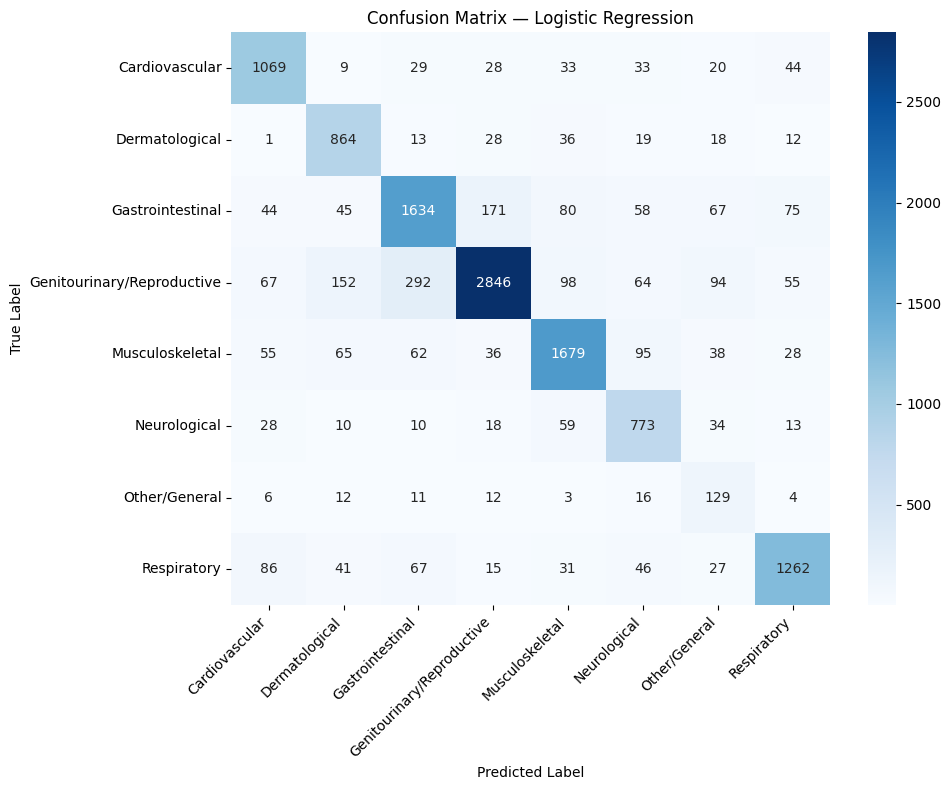

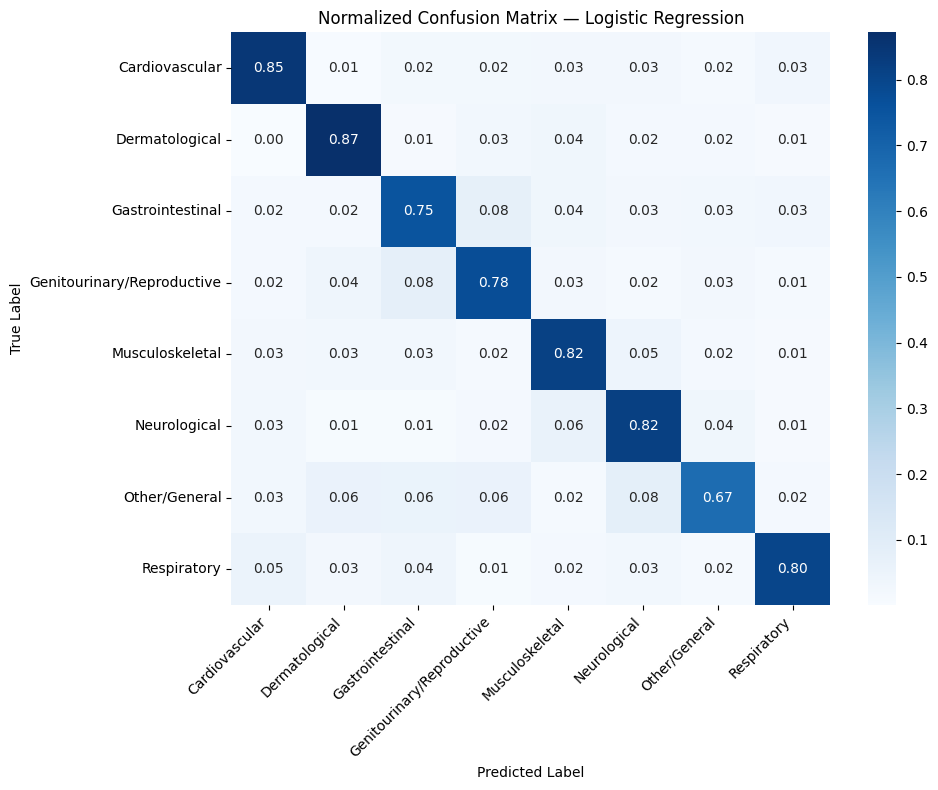

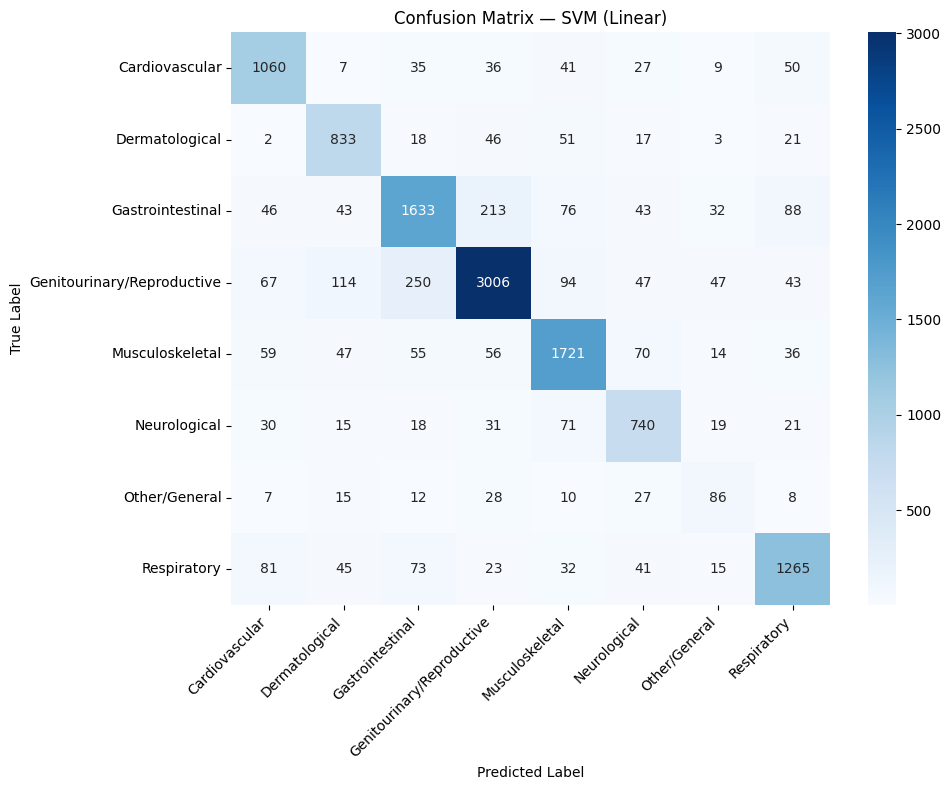

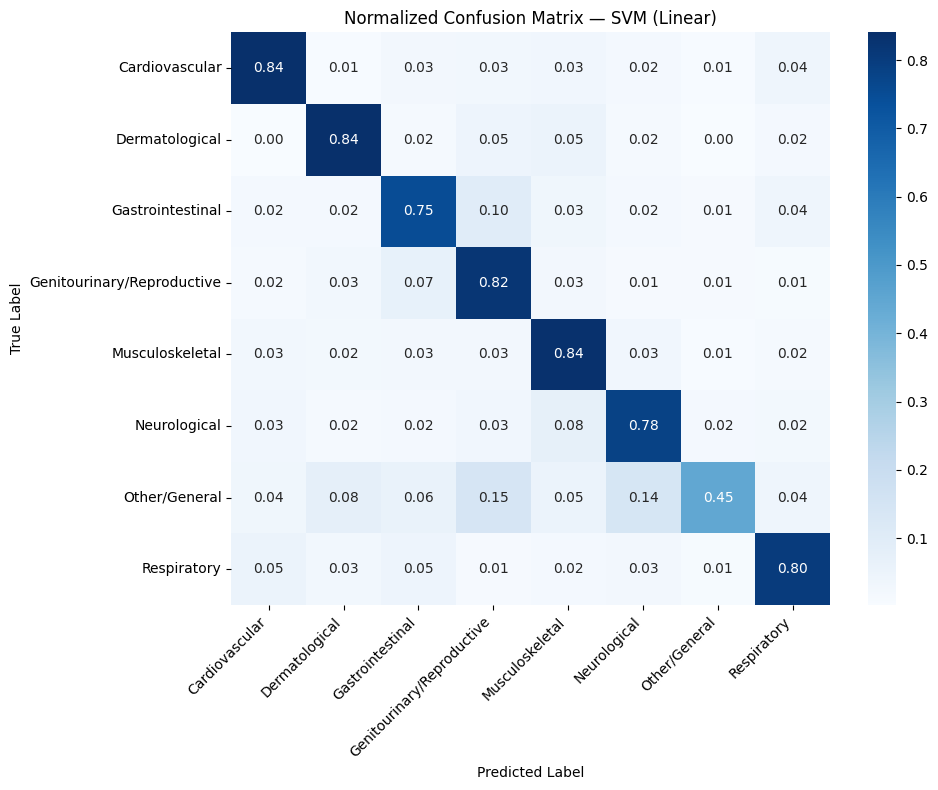

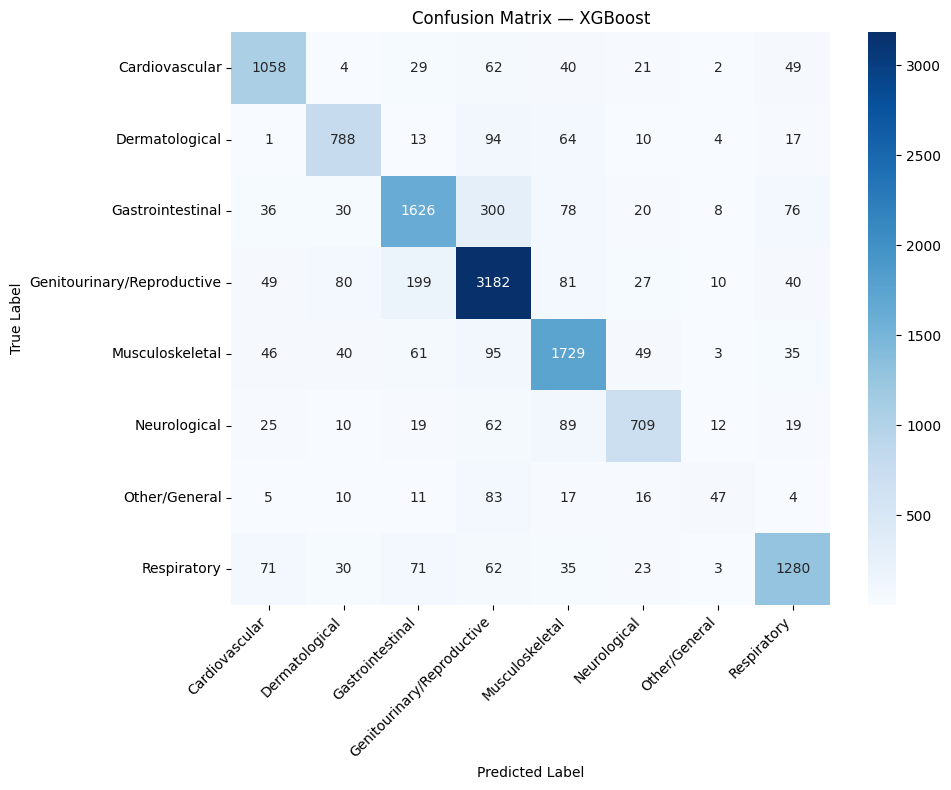

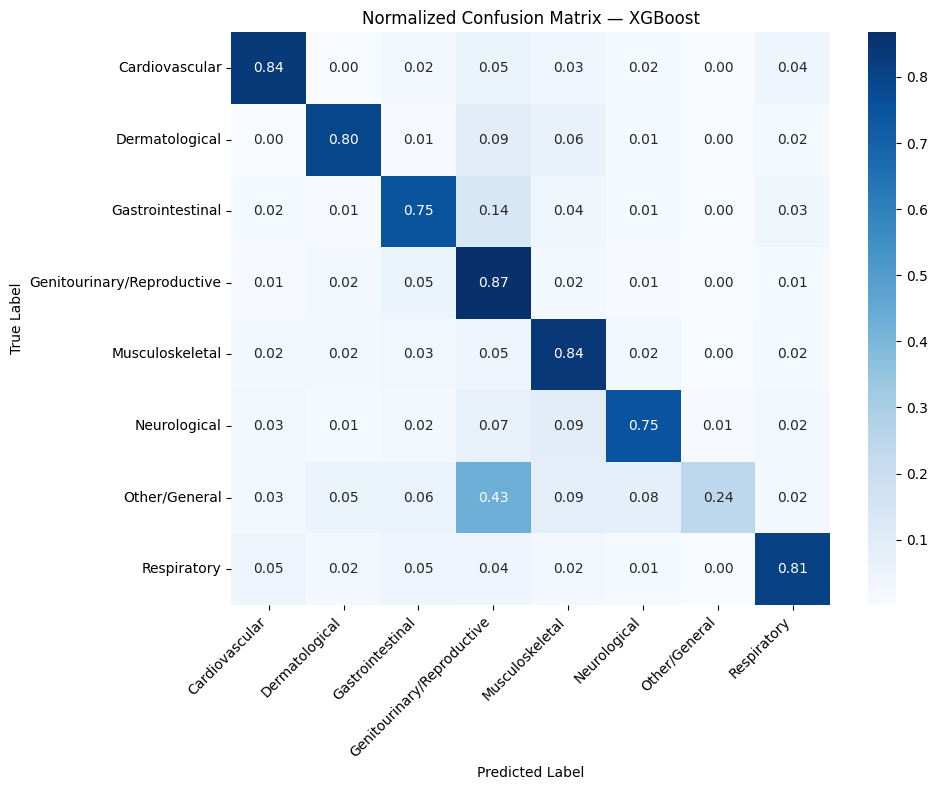

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

BASE_PATH = '/content/drive/MyDrive/Domain Classification'

top_models = ['Logistic Regression', 'SVM (Linear)', 'XGBoost']

for name in top_models:
    model = results[name]['model']

    if name == 'XGBoost':
        y_pred = le.inverse_transform(model.predict(X_val))
    else:
        y_pred = model.predict(X_val)

    labels = sorted(y_val.unique())
    cm = confusion_matrix(y_val, y_pred, labels=labels)

    safe_name = name.replace(" ", "_").replace("(", "").replace(")", "")

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
    plt.title(f'Confusion Matrix — {name}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(f'{BASE_PATH}/confusion_matrix_{safe_name}.png', dpi=150)
    plt.show()

    cm_norm = confusion_matrix(y_val, y_pred, labels=labels, normalize='true')
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=labels, yticklabels=labels)
    plt.title(f'Normalized Confusion Matrix — {name}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(f'{BASE_PATH}/confusion_matrix_normalized_{safe_name}.png', dpi=150)
    plt.show()

In [ ]:

import pandas as pd
from sklearn.metrics import classification_report, accuracy_score, f1_score

summary_rows = []
per_class_reports = {}

for name, res in results.items():
    model = res['model']

    if name == 'XGBoost':
        y_pred = le.inverse_transform(model.predict(X_val))
    else:
        y_pred = model.predict(X_val)

    acc = accuracy_score(y_val, y_pred)
    macro_f1 = f1_score(y_val, y_pred, average='macro')
    weighted_f1 = f1_score(y_val, y_pred, average='weighted')
    macro_precision = f1_score(y_val, y_pred, average='macro')

    report_dict = classification_report(y_val, y_pred, output_dict=True, zero_division=0)
    per_class_reports[name] = report_dict

    summary_rows.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Macro F1': round(macro_f1, 4),
        'Weighted F1': round(weighted_f1, 4),
        'Macro Precision': round(report_dict['macro avg']['precision'], 4),
        'Macro Recall': round(report_dict['macro avg']['recall'], 4),
        'Train Time (s)': round(res['time'], 1)
    })

summary_df = pd.DataFrame(summary_rows).sort_values('Macro F1', ascending=False).reset_index(drop=True)
print("="*80)
print("OVERALL MODEL COMPARISON")
print("="*80)
print(summary_df.to_string(index=False))

summary_df.to_csv('/content/drive/MyDrive/Domain Classification/model_comparison_summary.csv', index=False)

CHOSEN_MODEL = 'Logistic Regression'
print(f"\n{'='*80}")
print(f"PER-CLASS METRICS — {CHOSEN_MODEL}")
print(f"{'='*80}")

chosen_report = per_class_reports[CHOSEN_MODEL]
per_class_df = pd.DataFrame(chosen_report).transpose()
per_class_df = per_class_df.drop(['accuracy'], errors='ignore')
per_class_df = per_class_df.round(4)
print(per_class_df.to_string())

per_class_df.to_csv(f'/content/drive/MyDrive/Domain Classification/per_class_metrics_{CHOSEN_MODEL.replace(" ", "_")}.csv')

print(f"\n{'='*80}")
print("PER-CLASS F1 COMPARISON ACROSS MODELS")
print(f"{'='*80}")

f1_comparison = pd.DataFrame({
    name: {cls: report['f1-score'] for cls, report in per_class_reports[name].items()
           if cls not in ['accuracy', 'macro avg', 'weighted avg']}
    for name in per_class_reports
}).round(4)
print(f1_comparison.to_string())

f1_comparison.to_csv('/content/drive/MyDrive/Domain Classification/per_class_f1_comparison.csv')

print("\nAll summary files saved to Drive.")

OVERALL MODEL COMPARISON
              Model  Accuracy  Macro F1  Weighted F1  Macro Precision  Macro Recall  Train Time (s)
       SVM (Linear)    0.8038    0.7527       0.8047           0.7428        0.7647             9.0
Logistic Regression    0.7970    0.7522       0.8015           0.7328        0.7935            21.4
            XGBoost    0.8096    0.7497       0.8071           0.7767        0.7367          1361.0
      Random Forest    0.7586    0.6870       0.7543           0.7311        0.6773           407.7
        Naive Bayes    0.7506    0.6512       0.7433           0.6661        0.6437             0.3
                KNN    0.2904    0.0709       0.1392           0.7161        0.1324            48.2

PER-CLASS METRICS — Logistic Regression
                            precision  recall  f1-score  support
Cardiovascular                 0.7883  0.8451    0.8157   1265.0
Dermatological                 0.7212  0.8718    0.7894    991.0
Gastrointestinal               0.7715  

# Tuning

In [ ]:

from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, f1_score
import time

pipe = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', min_df=5, max_df=0.8)),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

param_grid = {
    'tfidf__max_features': [10000, 20000],
    'tfidf__ngram_range': [(1, 2), (1, 3)],
    'clf__C': [0.1, 1, 5, 10],
}

grid = GridSearchCV(
    pipe,
    param_grid,
    scoring='f1_macro',
    cv=3,
    n_jobs=-1,
    verbose=2
)

start = time.time()
grid.fit(train_df['input_clean'], y_train)
elapsed = time.time() - start

print(f"\nGrid search took {elapsed:.1f}s")
print(f"Best params: {grid.best_params_}")
print(f"Best CV macro F1: {grid.best_score_:.4f}")

best_model = grid.best_estimator_
y_pred = best_model.predict(val_df['input_clean'])

print(f"\nVal set Macro F1: {f1_score(y_val, y_pred, average='macro'):.4f}")
print(f"Val set Weighted F1: {f1_score(y_val, y_pred, average='weighted'):.4f}")
print(classification_report(y_val, y_pred, zero_division=0))

Fitting 3 folds for each of 16 candidates, totalling 48 fits

Grid search took 1056.2s
Best params: {'clf__C': 5, 'tfidf__max_features': 20000, 'tfidf__ngram_range': (1, 2)}
Best CV macro F1: 0.7542

Val set Macro F1: 0.7655
Val set Weighted F1: 0.8103
                            precision    recall  f1-score   support

            Cardiovascular       0.79      0.85      0.82      1265
            Dermatological       0.76      0.86      0.81       991
          Gastrointestinal       0.77      0.77      0.77      2174
Genitourinary/Reproductive       0.89      0.81      0.84      3668
           Musculoskeletal       0.83      0.83      0.83      2058
              Neurological       0.73      0.81      0.77       945
             Other/General       0.39      0.55      0.46       193
               Respiratory       0.84      0.81      0.82      1575

                  accuracy                           0.81     12869
                 macro avg       0.75      0.79      0.77     128

In [ ]:

import re
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score, classification_report

BOILERPLATE_PATTERNS = [
    r'\bhi\b', r'\bhello\b', r'\bdear doctor\b', r'\bthank you\b', r'\bthanks\b',
    r'\bhope (this|it) helps\b', r'\bplease help\b', r'\bkindly\b',
    r'\bgood morning\b', r'\bgood evening\b', r'\bdoctor\b'
]

def strip_boilerplate(text):
    for pattern in BOILERPLATE_PATTERNS:
        text = re.sub(pattern, ' ', text, flags=re.IGNORECASE)
    return re.sub(r'\s+', ' ', text).strip()

train_df['input_nostop'] = train_df['input_clean'].apply(strip_boilerplate)
val_df['input_nostop'] = val_df['input_clean'].apply(strip_boilerplate)

tfidf_b = TfidfVectorizer(max_features=20000, ngram_range=(1,2), min_df=5, max_df=0.8, stop_words='english')
Xb_train = tfidf_b.fit_transform(train_df['input_nostop'])
Xb_val = tfidf_b.transform(val_df['input_nostop'])

model_b = LogisticRegression(C=5, class_weight='balanced', max_iter=1000, random_state=42)
model_b.fit(Xb_train, y_train)
pred_b = model_b.predict(Xb_val)
print("A) Boilerplate-stripped macro F1:", round(f1_score(y_val, pred_b, average='macro'), 4))

tfidf_best = TfidfVectorizer(max_features=20000, ngram_range=(1,2), min_df=5, max_df=0.8, stop_words='english')
X_train_best = tfidf_best.fit_transform(train_df['input_clean'])
X_val_best = tfidf_best.transform(val_df['input_clean'])

sample_weights = train_df['confidence'].values

model_w = LogisticRegression(C=5, class_weight='balanced', max_iter=1000, random_state=42)
model_w.fit(X_train_best, y_train, sample_weight=sample_weights)
pred_w = model_w.predict(X_val_best)
print("B) Confidence-weighted macro F1:", round(f1_score(y_val, pred_w, average='macro'), 4))

strict_train = train_df[train_df['confidence'] >= 0.65]
print(f"\nC) Stricter threshold: {len(strict_train)}/{len(train_df)} rows kept ({len(strict_train)/len(train_df)*100:.1f}%)")

X_strict = tfidf_best.transform(strict_train['input_clean'])
model_c = LogisticRegression(C=5, class_weight='balanced', max_iter=1000, random_state=42)
model_c.fit(X_strict, strict_train['domain_label'])
pred_c = model_c.predict(X_val_best)
print("C) Stricter-threshold macro F1:", round(f1_score(y_val, pred_c, average='macro'), 4))

print(f"\nBaseline (current tuned model) macro F1: 0.7655")

A) Boilerplate-stripped macro F1: 0.7689
B) Confidence-weighted macro F1: 0.7713

C) Stricter threshold: 49914/60055 rows kept (83.1%)
C) Stricter-threshold macro F1: 0.7702

Baseline (current tuned model) macro F1: 0.7655


In [ ]:

tfidf_combo = TfidfVectorizer(max_features=20000, ngram_range=(1,2), min_df=5, max_df=0.8, stop_words='english')
X_combo_train = tfidf_combo.fit_transform(train_df['input_nostop'])
X_combo_val = tfidf_combo.transform(val_df['input_nostop'])

model_combo = LogisticRegression(C=5, class_weight='balanced', max_iter=1000, random_state=42)
model_combo.fit(X_combo_train, y_train, sample_weight=sample_weights)
pred_combo = model_combo.predict(X_combo_val)

print("D) Boilerplate-stripped + confidence-weighted macro F1:", round(f1_score(y_val, pred_combo, average='macro'), 4))
print("\nFull report:")
print(classification_report(y_val, pred_combo, zero_division=0))

D) Boilerplate-stripped + confidence-weighted macro F1: 0.772

Full report:
                            precision    recall  f1-score   support

            Cardiovascular       0.79      0.86      0.82      1265
            Dermatological       0.76      0.86      0.81       991
          Gastrointestinal       0.78      0.77      0.77      2174
Genitourinary/Reproductive       0.89      0.81      0.85      3668
           Musculoskeletal       0.82      0.84      0.83      2058
              Neurological       0.74      0.82      0.78       945
             Other/General       0.42      0.59      0.49       193
               Respiratory       0.84      0.81      0.82      1575

                  accuracy                           0.81     12869
                 macro avg       0.76      0.79      0.77     12869
              weighted avg       0.82      0.81      0.81     12869



In [ ]:

strict_train_nostop = strict_train.copy()
strict_train_nostop['input_nostop'] = strict_train_nostop['input_clean'].apply(strip_boilerplate)

X_final_train = tfidf_combo.transform(strict_train_nostop['input_nostop'])
final_weights = strict_train_nostop['confidence'].values

model_final = LogisticRegression(C=5, class_weight='balanced', max_iter=1000, random_state=42)
model_final.fit(X_final_train, strict_train_nostop['domain_label'], sample_weight=final_weights)
pred_final = model_final.predict(X_combo_val)

print("E) All three combined macro F1:", round(f1_score(y_val, pred_final, average='macro'), 4))

E) All three combined macro F1: 0.7691


In [ ]:

train_df['word_count'] = train_df['input_clean'].apply(lambda x: len(x.split()))
val_df['word_count'] = val_df['input_clean'].apply(lambda x: len(x.split()))

SHORT_THRESHOLD = 5

short_train = (train_df['word_count'] < SHORT_THRESHOLD).sum()
short_val = (val_df['word_count'] < SHORT_THRESHOLD).sum()

print(f"Train: {short_train}/{len(train_df)} rows under {SHORT_THRESHOLD} words ({short_train/len(train_df)*100:.2f}%)")
print(f"Val:   {short_val}/{len(val_df)} rows under {SHORT_THRESHOLD} words ({short_val/len(val_df)*100:.2f}%)")

val_df['pred'] = pred_combo
short_mask = val_df['word_count'] < SHORT_THRESHOLD
short_acc = (val_df.loc[short_mask, 'domain_label'] == val_df.loc[short_mask, 'pred']).mean()
normal_acc = (val_df.loc[~short_mask, 'domain_label'] == val_df.loc[~short_mask, 'pred']).mean()

print(f"\nAccuracy on short queries (<{SHORT_THRESHOLD} words): {short_acc:.4f} (n={short_mask.sum()})")
print(f"Accuracy on normal-length queries: {normal_acc:.4f} (n={(~short_mask).sum()})")

print("\nSample short queries:")
for _, row in val_df[short_mask].head(10).iterrows():
    print(f"[{row['domain_label']} -> {row['pred']}] {row['input_clean']}")

Train: 51/60055 rows under 5 words (0.08%)
Val:   12/12869 rows under 5 words (0.09%)

Accuracy on short queries (<5 words): 0.6667 (n=12)
Accuracy on normal-length queries: 0.8124 (n=12857)

Sample short queries:
[Musculoskeletal -> Musculoskeletal] mri report findings
[Other/General -> Other/General] case history
[Genitourinary/Reproductive -> Genitourinary/Reproductive] infertility doubt
[Musculoskeletal -> Musculoskeletal] what does rheumatoid factor
[Neurological -> Neurological] topic on concussions
[Gastrointestinal -> Musculoskeletal] dmsa test findings
[Genitourinary/Reproductive -> Genitourinary/Reproductive] blood test results
[Genitourinary/Reproductive -> Genitourinary/Reproductive] sex
[Other/General -> Other/General] psychological problem
[Musculoskeletal -> Genitourinary/Reproductive] left kidney


In [ ]:

from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

svm_base = LinearSVC(class_weight='balanced', random_state=42, max_iter=2000)
svm_calibrated = CalibratedClassifierCV(svm_base, cv=3)
svm_calibrated.fit(X_combo_train, train_df['domain_label'], sample_weight=sample_weights)

proba_logreg = model_combo.predict_proba(X_combo_val)
proba_svm = svm_calibrated.predict_proba(X_combo_val)

proba_avg = (proba_logreg + proba_svm) / 2
pred_ensemble = model_combo.classes_[proba_avg.argmax(axis=1)]

print("G) Soft-voting ensemble macro F1:", round(f1_score(y_val, pred_ensemble, average='macro'), 4))
print("\nFull report:")
print(classification_report(y_val, pred_ensemble, zero_division=0))
print(f"\nComparison — Current best (D): 0.7720")

G) Soft-voting ensemble macro F1: 0.7757

Full report:
                            precision    recall  f1-score   support

            Cardiovascular       0.81      0.85      0.83      1265
            Dermatological       0.78      0.85      0.82       991
          Gastrointestinal       0.79      0.77      0.78      2174
Genitourinary/Reproductive       0.87      0.84      0.85      3668
           Musculoskeletal       0.83      0.85      0.84      2058
              Neurological       0.77      0.81      0.79       945
             Other/General       0.52      0.44      0.48       193
               Respiratory       0.85      0.81      0.83      1575

                  accuracy                           0.82     12869
                 macro avg       0.78      0.78      0.78     12869
              weighted avg       0.82      0.82      0.82     12869


Comparison — Current best (D): 0.7720


In [ ]:

from sklearn.feature_selection import SelectKBest, chi2

for k in [5000, 10000, 15000]:
    selector = SelectKBest(chi2, k=k)
    X_train_sel = selector.fit_transform(X_combo_train, train_df['domain_label'])
    X_val_sel = selector.transform(X_combo_val)

    model_sel = LogisticRegression(C=5, class_weight='balanced', max_iter=1000, random_state=42)
    model_sel.fit(X_train_sel, train_df['domain_label'], sample_weight=sample_weights)
    pred_sel = model_sel.predict(X_val_sel)

    macro_f1_sel = f1_score(y_val, pred_sel, average='macro')
    print(f"k={k}: macro F1 = {macro_f1_sel:.4f}")

print(f"\nComparison — Current best (G, ensemble): 0.7757")
print(f"Comparison — D (LogReg alone, full 20k features): 0.7720")

k=5000: macro F1 = 0.7652
k=10000: macro F1 = 0.7716
k=15000: macro F1 = 0.7716

Comparison — Current best (G, ensemble): 0.7757
Comparison — D (LogReg alone, full 20k features): 0.7720


# Re-evaluate

In [ ]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix
)



acc = accuracy_score(y_val, pred_ensemble)
macro_f1 = f1_score(y_val, pred_ensemble, average='macro')
weighted_f1 = f1_score(y_val, pred_ensemble, average='weighted')
macro_precision = precision_score(y_val, pred_ensemble, average='macro')
macro_recall = recall_score(y_val, pred_ensemble, average='macro')
weighted_precision = precision_score(y_val, pred_ensemble, average='weighted')
weighted_recall = recall_score(y_val, pred_ensemble, average='weighted')

print("="*70)
print("FINAL MODEL (G — Soft-Voting Ensemble) — OVERALL METRICS")
print("="*70)

print(f"Accuracy:            {acc:.4f}")
print(f"Macro F1:            {macro_f1:.4f}")
print(f"Weighted F1:         {weighted_f1:.4f}")
print(f"Macro Precision:     {macro_precision:.4f}")
print(f"Macro Recall:        {macro_recall:.4f}")
print(f"Weighted Precision:  {weighted_precision:.4f}")
print(f"Weighted Recall:     {weighted_recall:.4f}")

print("\n" + "="*70)
print("PER-CLASS METRICS")
print("="*70)
report_dict = classification_report(y_val, pred_ensemble, output_dict=True, zero_division=0)
per_class_df = pd.DataFrame(report_dict).transpose().round(4)
print(per_class_df.to_string())

labels = sorted(y_val.unique())
cm = confusion_matrix(y_val, pred_ensemble, labels=labels)
cm_df = pd.DataFrame(cm, index=labels, columns=labels)
print("\n" + "="*70)
print("CONFUSION MATRIX (raw counts)")
print("="*70)
print(cm_df.to_string())

print("\n" + "="*70)
print("EXPERIMENT PROGRESSION SUMMARY")
print("="*70)
progression = pd.DataFrame([
    {'Stage': 'Baseline LogReg', 'Macro F1': 0.7541, 'Notes': 'Default hyperparameters, 10k features'},
    {'Stage': 'Tuned (GridSearchCV)', 'Macro F1': 0.7655, 'Notes': 'C=5, 20k features, bigrams'},
    {'Stage': 'A: Boilerplate stripped', 'Macro F1': 0.7689, 'Notes': 'Removed greeting/closing phrases'},
    {'Stage': 'B: Confidence-weighted', 'Macro F1': 0.7713, 'Notes': 'sample_weight = zero-shot confidence'},
    {'Stage': 'C: Stricter threshold (0.65)', 'Macro F1': 0.7702, 'Notes': '83.1% of rows kept'},
    {'Stage': 'D: A + B combined', 'Macro F1': 0.7720, 'Notes': 'Final single-model result'},
    {'Stage': 'E: A + B + C stacked', 'Macro F1': 0.7691, 'Notes': 'Worse — stricter filtering redundant with weighting'},
    {'Stage': 'F: Short-query filtering', 'Macro F1': None, 'Notes': 'Not material — 0.08% of data, skipped'},
    {'Stage': 'G: Ensemble (LogReg + SVM)', 'Macro F1': 0.7757, 'Notes': 'FINAL MODEL — best result'},
    {'Stage': 'H: Chi-square selection (k=5k/10k/15k)', 'Macro F1': 0.7716, 'Notes': 'Best of the three (k=10k/15k); did not beat D or G'},
])
print(progression.to_string(index=False))

per_class_df.to_csv('/content/drive/MyDrive/Domain Classification/final_model_per_class_metrics.csv')
cm_df.to_csv('/content/drive/MyDrive/Domain Classification/final_model_confusion_matrix.csv')
progression.to_csv('/content/drive/MyDrive/Domain Classification/experiment_progression_summary.csv', index=False)

print("\nAll evaluation outputs saved to Drive.")

FINAL MODEL (G — Soft-Voting Ensemble) — OVERALL METRICS
Accuracy:            0.8194
Macro F1:            0.7757
Weighted F1:         0.8191
Macro Precision:     0.7754
Macro Recall:        0.7777
Weighted Precision:  0.8197
Weighted Recall:     0.8194

PER-CLASS METRICS
                            precision  recall  f1-score     support
Cardiovascular                 0.8057  0.8458    0.8253   1265.0000
Dermatological                 0.7822  0.8517    0.8155    991.0000
Gastrointestinal               0.7869  0.7695    0.7781   2174.0000
Genitourinary/Reproductive     0.8669  0.8378    0.8521   3668.0000
Musculoskeletal                0.8278  0.8528    0.8401   2058.0000
Neurological                   0.7688  0.8127    0.7901    945.0000
Other/General                  0.5183  0.4404    0.4762    193.0000
Respiratory                    0.8468  0.8108    0.8284   1575.0000
accuracy                       0.8194  0.8194    0.8194      0.8194
macro avg                      0.7754  0.7777   

In [ ]:

import joblib

BASE_PATH = '/content/drive/MyDrive/Domain Classification'

joblib.dump(model_combo, f'{BASE_PATH}/final_model_logreg.pkl')
joblib.dump(svm_calibrated, f'{BASE_PATH}/final_model_svm_calibrated.pkl')
joblib.dump(tfidf_combo, f'{BASE_PATH}/final_tfidf_vectorizer.pkl')

print("Saved: final_model_logreg.pkl, final_model_svm_calibrated.pkl, final_tfidf_vectorizer.pkl")

Saved: final_model_logreg.pkl, final_model_svm_calibrated.pkl, final_tfidf_vectorizer.pkl


# Reconnect cell

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import re
import joblib
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

BASE_PATH = '/content/drive/MyDrive/Domain Classification'

labeled_df = pd.read_csv(f'{BASE_PATH}/labeled_checkpoint.csv')
clean_df = labeled_df[labeled_df['confidence'] >= 0.5].reset_index(drop=True)

train_df, temp_df = train_test_split(clean_df, test_size=0.30, stratify=clean_df['domain_label'], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['domain_label'], random_state=42)

def clean_text(text):
    text = str(text)
    text = re.sub(r'\bchat\s*doctor\b', ' ', text, flags=re.IGNORECASE)
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'\\u[0-9a-fA-F]{4}', ' ', text)
    text = text.encode('ascii', 'ignore').decode('ascii')
    text = re.sub(r'[^a-z0-9\s\.\,\?\!]', ' ', text)
    text = re.sub(r'([\.\,\?\!])\1+', r'\1', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

BOILERPLATE_PATTERNS = [
    r'\bhi\b', r'\bhello\b', r'\bdear doctor\b', r'\bthank you\b', r'\bthanks\b',
    r'\bhope (this|it) helps\b', r'\bplease help\b', r'\bkindly\b',
    r'\bgood morning\b', r'\bgood evening\b', r'\bdoctor\b'
]

def strip_boilerplate(text):
    for pattern in BOILERPLATE_PATTERNS:
        text = re.sub(pattern, ' ', text, flags=re.IGNORECASE)
    return re.sub(r'\s+', ' ', text).strip()

for split_df in [train_df, val_df, test_df]:
    split_df['input_clean'] = split_df['input'].apply(clean_text)
    split_df['input_nostop'] = split_df['input_clean'].apply(strip_boilerplate)

y_train = train_df['domain_label']
y_val = val_df['domain_label']

model_combo = joblib.load(f'{BASE_PATH}/final_model_logreg.pkl')
svm_calibrated = joblib.load(f'{BASE_PATH}/final_model_svm_calibrated.pkl')
tfidf_combo = joblib.load(f'{BASE_PATH}/final_tfidf_vectorizer.pkl')

X_combo_train = tfidf_combo.transform(train_df['input_nostop'])
X_combo_val = tfidf_combo.transform(val_df['input_nostop'])

proba_logreg = model_combo.predict_proba(X_combo_val)
proba_svm = svm_calibrated.predict_proba(X_combo_val)
proba_avg = (proba_logreg + proba_svm) / 2
pred_ensemble = model_combo.classes_[proba_avg.argmax(axis=1)]
pred_combo = model_combo.predict(X_combo_val)

print("Reconnected using saved models.")
print("G) Ensemble macro F1:", round(f1_score(y_val, pred_ensemble, average='macro'), 4))

Mounted at /content/drive
Reconnected using saved models.
G) Ensemble macro F1: 0.7757


# Confidence Theshhold

In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, accuracy_score

ensemble_confidence = proba_avg.max(axis=1)

thresholds = [0.0, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
results_table = []

for t in thresholds:
    mask = ensemble_confidence >= t
    coverage = mask.mean()

    if mask.sum() == 0:
        continue

    y_val_subset = y_val[mask]
    pred_subset = pred_ensemble[mask]

    acc = accuracy_score(y_val_subset, pred_subset)
    macro_f1 = f1_score(y_val_subset, pred_subset, average='macro', zero_division=0)

    results_table.append({
        'Threshold': t,
        'Coverage': f"{coverage*100:.1f}%",
        'N': mask.sum(),
        'Accuracy': round(acc, 4),
        'Macro F1': round(macro_f1, 4)
    })

results_df = pd.DataFrame(results_table)
print(results_df.to_string(index=False))

 Threshold Coverage     N  Accuracy  Macro F1
       0.0   100.0% 12869    0.8194    0.7757
       0.3    98.4% 12661    0.8278    0.7860
       0.4    94.1% 12108    0.8475    0.8110
       0.5    86.9% 11187    0.8733    0.8444
       0.6    77.9% 10027    0.9012    0.8716
       0.7    68.5%  8812    0.9298    0.8858
       0.8    57.3%  7375    0.9540    0.8901
       0.9    40.8%  5254    0.9777    0.8535


In [ ]:

THRESHOLD = 0.7

mask = ensemble_confidence >= THRESHOLD
per_class_coverage = pd.DataFrame({
    'true_label': y_val,
    'covered': mask
}).groupby('true_label')['covered'].mean().sort_values()

print(f"Per-class coverage at threshold {THRESHOLD}:")
print((per_class_coverage * 100).round(1))

Per-class coverage at threshold 0.7:
true_label
Other/General                 16.1
Neurological                  61.3
Gastrointestinal              62.0
Dermatological                68.6
Respiratory                   69.0
Cardiovascular                71.9
Genitourinary/Reproductive    72.6
Musculoskeletal               73.6
Name: covered, dtype: float64


# New Evaluation

In [ ]:

import pandas as pd
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix

THRESHOLD = 0.7
mask = ensemble_confidence >= THRESHOLD

y_val_filtered = y_val[mask]
pred_filtered = pred_ensemble[mask]

coverage = mask.mean()

print("="*70)
print(f"FINAL RESULTS — Selective Prediction @ Confidence Threshold {THRESHOLD}")
print(f"Coverage: {coverage*100:.1f}% ({mask.sum()}/{len(mask)} validation samples)")
print("="*70)

acc = accuracy_score(y_val_filtered, pred_filtered)
macro_f1 = f1_score(y_val_filtered, pred_filtered, average='macro')
weighted_f1 = f1_score(y_val_filtered, pred_filtered, average='weighted')

print(f"Accuracy:     {acc:.4f}")
print(f"Macro F1:     {macro_f1:.4f}")
print(f"Weighted F1:  {weighted_f1:.4f}")

print("\n" + "="*70)
print("PER-CLASS METRICS (filtered subset)")
print("="*70)
report_dict = classification_report(y_val_filtered, pred_filtered, output_dict=True, zero_division=0)
per_class_df = pd.DataFrame(report_dict).transpose().round(4)
print(per_class_df.to_string())

per_class_coverage = pd.DataFrame({'true_label': y_val, 'covered': mask}).groupby('true_label')['covered'].mean()
print("\n" + "="*70)
print("PER-CLASS COVERAGE (% of each class retained at this threshold)")
print("="*70)
print((per_class_coverage * 100).round(1).to_string())

labels = sorted(y_val_filtered.unique())
cm = confusion_matrix(y_val_filtered, pred_filtered, labels=labels)
cm_df = pd.DataFrame(cm, index=labels, columns=labels)
print("\n" + "="*70)
print("CONFUSION MATRIX (filtered subset)")
print("="*70)
print(cm_df.to_string())

from google.colab import files

per_class_df.to_csv('/content/final_metrics_threshold_0.7.csv')
cm_df.to_csv('/content/confusion_matrix_threshold_0.7.csv')
per_class_coverage.to_csv('/content/per_class_coverage_threshold_0.7.csv')

files.download('/content/final_metrics_threshold_0.7.csv')
files.download('/content/confusion_matrix_threshold_0.7.csv')
files.download('/content/per_class_coverage_threshold_0.7.csv')

print("\nFiles downloaded.")

FINAL RESULTS — Selective Prediction @ Confidence Threshold 0.7
Coverage: 68.5% (8812/12869 validation samples)
Accuracy:     0.9298
Macro F1:     0.8858
Weighted F1:  0.9297

PER-CLASS METRICS (filtered subset)
                            precision  recall  f1-score    support
Cardiovascular                 0.9101  0.9451    0.9272   910.0000
Dermatological                 0.8997  0.9632    0.9304   680.0000
Gastrointestinal               0.8985  0.8865    0.8925  1348.0000
Genitourinary/Reproductive     0.9567  0.9366    0.9465  2664.0000
Musculoskeletal                0.9403  0.9465    0.9434  1514.0000
Neurological                   0.9068  0.9240    0.9153   579.0000
Other/General                  0.6538  0.5484    0.5965    31.0000
Respiratory                    0.9453  0.9236    0.9343  1086.0000
accuracy                       0.9298  0.9298    0.9298     0.9298
macro avg                      0.8889  0.8842    0.8858  8812.0000
weighted avg                   0.9300  0.9298    0.

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Files downloaded.


In [ ]:

from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix
import pandas as pd

X_combo_test = tfidf_combo.transform(test_df['input_nostop'])
y_test = test_df['domain_label']

proba_logreg_test = model_combo.predict_proba(X_combo_test)
proba_svm_test = svm_calibrated.predict_proba(X_combo_test)
proba_avg_test = (proba_logreg_test + proba_svm_test) / 2
pred_ensemble_test = model_combo.classes_[proba_avg_test.argmax(axis=1)]

test_confidence = proba_avg_test.max(axis=1)

print("="*70)
print("TEST SET — FULL COVERAGE")
print("="*70)
print(f"Accuracy:    {accuracy_score(y_test, pred_ensemble_test):.4f}")
print(f"Macro F1:    {f1_score(y_test, pred_ensemble_test, average='macro'):.4f}")
print(f"Weighted F1: {f1_score(y_test, pred_ensemble_test, average='weighted'):.4f}")

THRESHOLD = 0.7
mask_test = test_confidence >= THRESHOLD
coverage_test = mask_test.mean()

y_test_filtered = y_test[mask_test]
pred_test_filtered = pred_ensemble_test[mask_test]

print("\n" + "="*70)
print(f"TEST SET — Selective Prediction @ Threshold {THRESHOLD}")
print(f"Coverage: {coverage_test*100:.1f}% ({mask_test.sum()}/{len(mask_test)} test samples)")
print("="*70)
print(f"Accuracy:    {accuracy_score(y_test_filtered, pred_test_filtered):.4f}")
print(f"Macro F1:    {f1_score(y_test_filtered, pred_test_filtered, average='macro'):.4f}")
print(f"Weighted F1: {f1_score(y_test_filtered, pred_test_filtered, average='weighted'):.4f}")

print("\nPer-class report (filtered):")
print(classification_report(y_test_filtered, pred_test_filtered, zero_division=0))

per_class_cov_test = pd.DataFrame({'true_label': y_test, 'covered': mask_test}).groupby('true_label')['covered'].mean()
print("\nPer-class coverage (test set):")
print((per_class_cov_test * 100).round(1).to_string())

TEST SET — FULL COVERAGE
Accuracy:    0.8139
Macro F1:    0.7628
Weighted F1: 0.8140

TEST SET — Selective Prediction @ Threshold 0.7
Coverage: 68.1% (8763/12870 test samples)
Accuracy:    0.9288
Macro F1:    0.8952
Weighted F1: 0.9288

Per-class report (filtered):
                            precision    recall  f1-score   support

            Cardiovascular       0.91      0.93      0.92       904
            Dermatological       0.89      0.97      0.93       669
          Gastrointestinal       0.90      0.89      0.90      1328
Genitourinary/Reproductive       0.96      0.93      0.95      2705
           Musculoskeletal       0.93      0.95      0.94      1488
              Neurological       0.90      0.92      0.91       545
             Other/General       0.74      0.65      0.69        31
               Respiratory       0.94      0.92      0.93      1093

                  accuracy                           0.93      8763
                 macro avg       0.90      0.90     

In [ ]:

import pandas as pd
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix
from google.colab import files

THRESHOLD = 0.7


mask_val = ensemble_confidence >= THRESHOLD
y_val_filt = y_val[mask_val]
pred_val_filt = pred_ensemble[mask_val]


X_combo_test = tfidf_combo.transform(test_df['input_nostop'])
y_test = test_df['domain_label']

proba_logreg_test = model_combo.predict_proba(X_combo_test)
proba_svm_test = svm_calibrated.predict_proba(X_combo_test)
proba_avg_test = (proba_logreg_test + proba_svm_test) / 2
pred_ensemble_test = model_combo.classes_[proba_avg_test.argmax(axis=1)]
test_confidence = proba_avg_test.max(axis=1)

mask_test = test_confidence >= THRESHOLD
y_test_filt = y_test[mask_test]
pred_test_filt = pred_ensemble_test[mask_test]


summary = pd.DataFrame([
    {
        'Split': 'Validation', 'Coverage': '100%',
        'Accuracy': round(accuracy_score(y_val, pred_ensemble), 4),
        'Macro F1': round(f1_score(y_val, pred_ensemble, average='macro'), 4),
        'Weighted F1': round(f1_score(y_val, pred_ensemble, average='weighted'), 4)
    },
    {
        'Split': f'Validation @ {THRESHOLD}', 'Coverage': f'{mask_val.mean()*100:.1f}%',
        'Accuracy': round(accuracy_score(y_val_filt, pred_val_filt), 4),
        'Macro F1': round(f1_score(y_val_filt, pred_val_filt, average='macro'), 4),
        'Weighted F1': round(f1_score(y_val_filt, pred_val_filt, average='weighted'), 4)
    },
    {
        'Split': 'Test', 'Coverage': '100%',
        'Accuracy': round(accuracy_score(y_test, pred_ensemble_test), 4),
        'Macro F1': round(f1_score(y_test, pred_ensemble_test, average='macro'), 4),
        'Weighted F1': round(f1_score(y_test, pred_ensemble_test, average='weighted'), 4)
    },
    {
        'Split': f'Test @ {THRESHOLD}', 'Coverage': f'{mask_test.mean()*100:.1f}%',
        'Accuracy': round(accuracy_score(y_test_filt, pred_test_filt), 4),
        'Macro F1': round(f1_score(y_test_filt, pred_test_filt, average='macro'), 4),
        'Weighted F1': round(f1_score(y_test_filt, pred_test_filt, average='weighted'), 4)
    },
])

print("="*70)
print("SUMMARY: VALIDATION vs TEST, FULL vs SELECTIVE (threshold 0.7)")
print("="*70)
print(summary.to_string(index=False))


print("\n" + "="*70)
print(f"PER-CLASS METRICS — TEST SET @ THRESHOLD {THRESHOLD} (headline result)")
print("="*70)
report_dict = classification_report(y_test_filt, pred_test_filt, output_dict=True, zero_division=0)
per_class_df = pd.DataFrame(report_dict).transpose().round(4)
print(per_class_df.to_string())


per_class_cov = pd.DataFrame({'true_label': y_test, 'covered': mask_test}).groupby('true_label')['covered'].mean()
print("\n" + "="*70)
print("PER-CLASS COVERAGE — TEST SET (for limitations/discussion)")
print("="*70)
print((per_class_cov * 100).round(1).to_string())


labels = sorted(y_test_filt.unique())
cm = confusion_matrix(y_test_filt, pred_test_filt, labels=labels)
cm_df = pd.DataFrame(cm, index=labels, columns=labels)
print("\n" + "="*70)
print(f"CONFUSION MATRIX — TEST SET @ THRESHOLD {THRESHOLD}")
print("="*70)
print(cm_df.to_string())


summary.to_csv('/content/FINAL_summary_val_vs_test.csv', index=False)
per_class_df.to_csv('/content/FINAL_per_class_metrics_test.csv')
per_class_cov.to_csv('/content/FINAL_per_class_coverage_test.csv')
cm_df.to_csv('/content/FINAL_confusion_matrix_test.csv')

for f in ['FINAL_summary_val_vs_test.csv', 'FINAL_per_class_metrics_test.csv',
          'FINAL_per_class_coverage_test.csv', 'FINAL_confusion_matrix_test.csv']:
    files.download(f'/content/{f}')

print("\nAll final results saved and downloaded.")

SUMMARY: VALIDATION vs TEST, FULL vs SELECTIVE (threshold 0.7)
           Split Coverage  Accuracy  Macro F1  Weighted F1
      Validation     100%    0.8194    0.7757       0.8191
Validation @ 0.7    68.5%    0.9298    0.8858       0.9297
            Test     100%    0.8139    0.7628       0.8140
      Test @ 0.7    68.1%    0.9288    0.8952       0.9288

PER-CLASS METRICS — TEST SET @ THRESHOLD 0.7 (headline result)
                            precision  recall  f1-score    support
Cardiovascular                 0.9083  0.9314    0.9197   904.0000
Dermatological                 0.8878  0.9701    0.9271   669.0000
Gastrointestinal               0.8991  0.8923    0.8957  1328.0000
Genitourinary/Reproductive     0.9618  0.9316    0.9465  2705.0000
Musculoskeletal                0.9334  0.9509    0.9421  1488.0000
Neurological                   0.9007  0.9156    0.9081   545.0000
Other/General                  0.7407  0.6452    0.6897    31.0000
Respiratory                    0.9430  0.9

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


All final results saved and downloaded.


# SHAP

TOP 15 WORDS DRIVING CLASSIFICATION — PER DOMAIN

Cardiovascular:
  heart                          0.3034
  chest                          0.1678
  blood                          0.0918
  pressure                       0.0638
  blood pressure                 0.0611
  fever                          0.0596
  dizziness                      0.0384
  rash                           0.0375
  cancer                         0.0354
  stomach                        0.0337
  liver                          0.0335
  infection                      0.0301
  tongue                         0.0286
  high                           0.0284
  normal                         0.0276

Dermatological:
  pain                           0.1627
  rash                           0.1502
  skin                           0.1172
  pimples                        0.0571
  heart                          0.0571
  cough                          0.0520
  blood                          0.0498
  body                           0.04

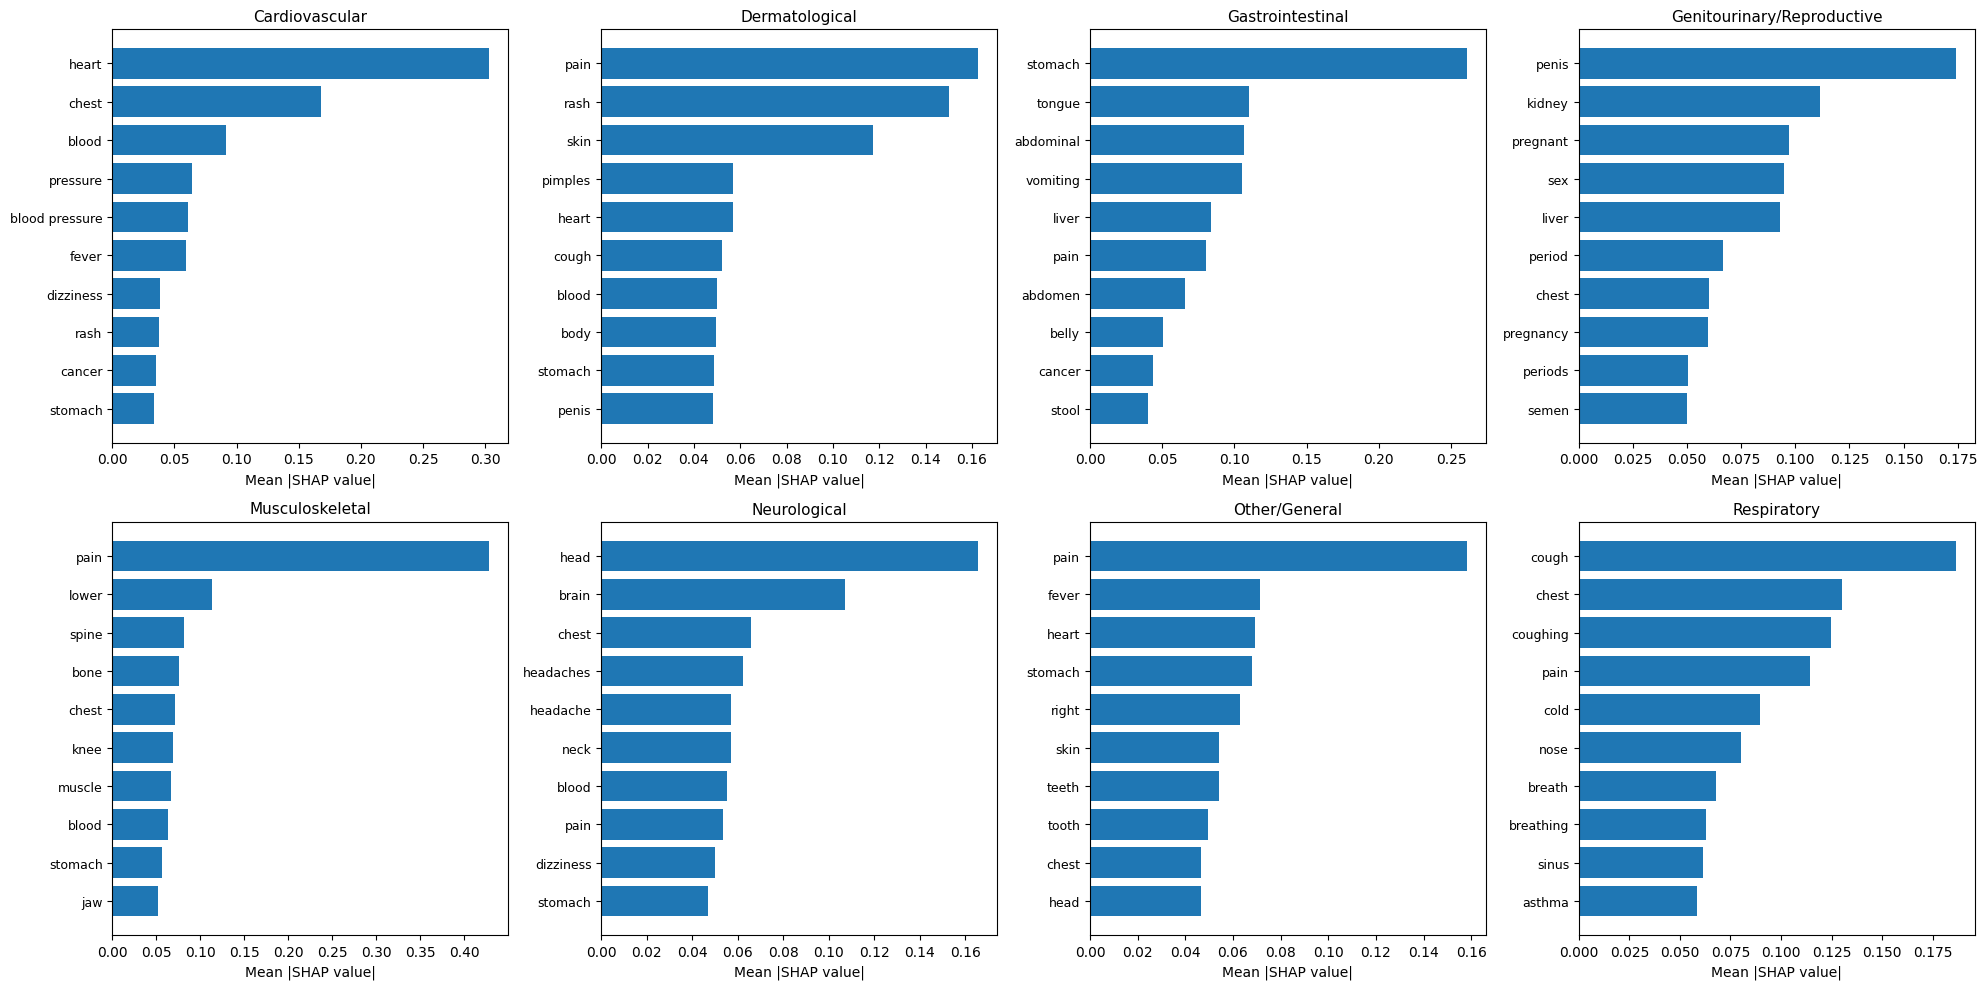

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


SHAP analysis complete. Files downloaded.


In [ ]:

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


background = shap.sample(X_combo_train, 200, random_state=42)

explainer = shap.LinearExplainer(model_combo, background)

SAMPLE_SIZE = 1000
sample_idx = np.random.RandomState(42).choice(X_combo_val.shape[0], SAMPLE_SIZE, replace=False)
X_sample = X_combo_val[sample_idx]

shap_values = explainer.shap_values(X_sample)

feature_names = tfidf_combo.get_feature_names_out()
classes = model_combo.classes_

if not isinstance(shap_values, list):
    shap_values = [shap_values[:, :, i] for i in range(len(classes))]

top_words_per_class = {}

for i, cls in enumerate(classes):
    mean_abs_shap = np.abs(shap_values[i]).mean(axis=0)
    top_idx = np.argsort(mean_abs_shap)[-15:][::-1]
    top_words_per_class[cls] = [(feature_names[j], round(mean_abs_shap[j], 4)) for j in top_idx]

print("="*70)
print("TOP 15 WORDS DRIVING CLASSIFICATION — PER DOMAIN")
print("="*70)
for cls, words in top_words_per_class.items():
    print(f"\n{cls}:")
    for word, score in words:
        print(f"  {word:30s} {score:.4f}")

rows = []
for cls, words in top_words_per_class.items():
    for rank, (word, score) in enumerate(words, 1):
        rows.append({'Domain': cls, 'Rank': rank, 'Word/Phrase': word, 'Mean |SHAP|': score})

top_words_df = pd.DataFrame(rows)
top_words_df.to_csv('/content/shap_top_words_per_domain.csv', index=False)

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, cls in enumerate(classes):
    words, scores = zip(*top_words_per_class[cls][:10])
    axes[i].barh(range(len(words)), scores)
    axes[i].set_yticks(range(len(words)))
    axes[i].set_yticklabels(words, fontsize=9)
    axes[i].invert_yaxis()
    axes[i].set_title(cls, fontsize=11)
    axes[i].set_xlabel('Mean |SHAP value|')

plt.tight_layout()
plt.savefig('/content/shap_top_words_all_domains.png', dpi=150, bbox_inches='tight')
plt.show()

from google.colab import files
files.download('/content/shap_top_words_per_domain.csv')
files.download('/content/shap_top_words_all_domains.png')

print("\nSHAP analysis complete. Files downloaded.")

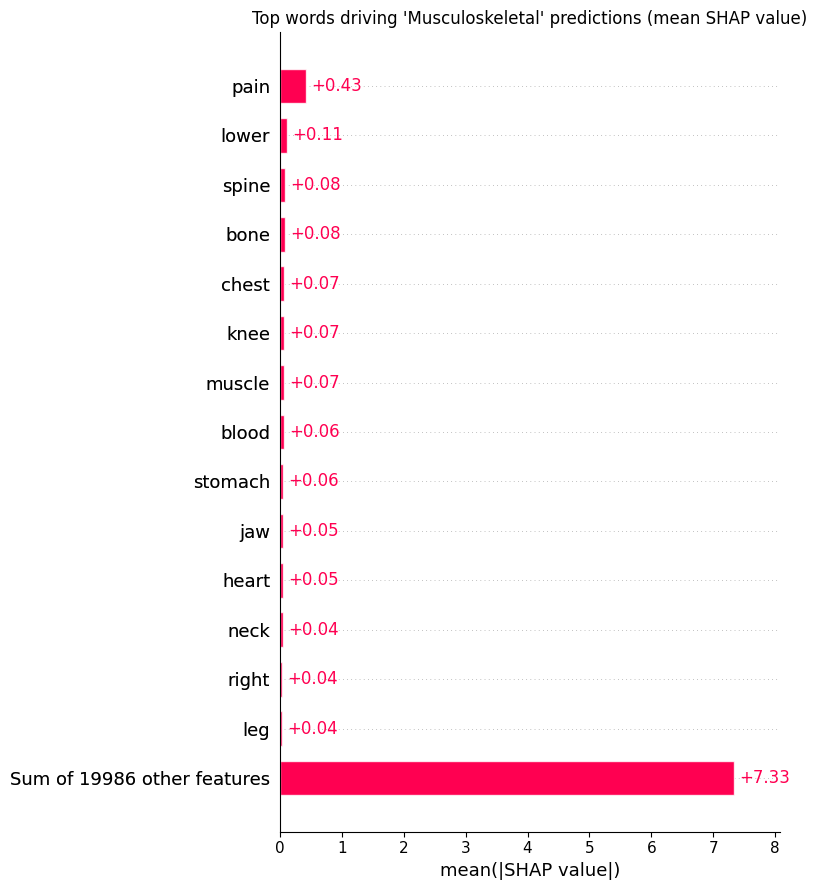

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

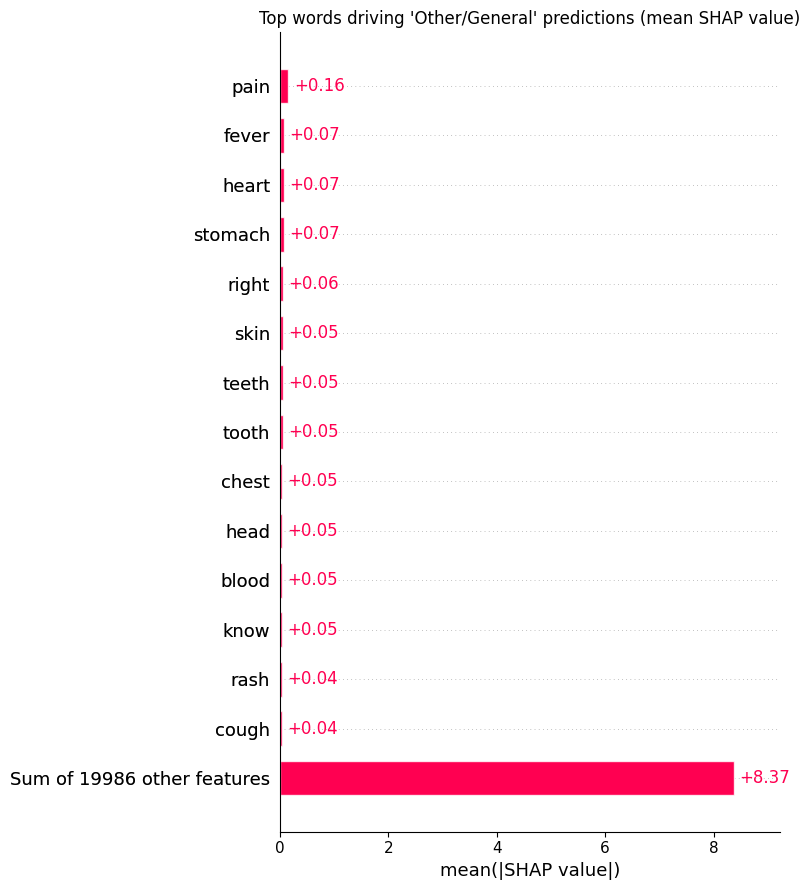

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

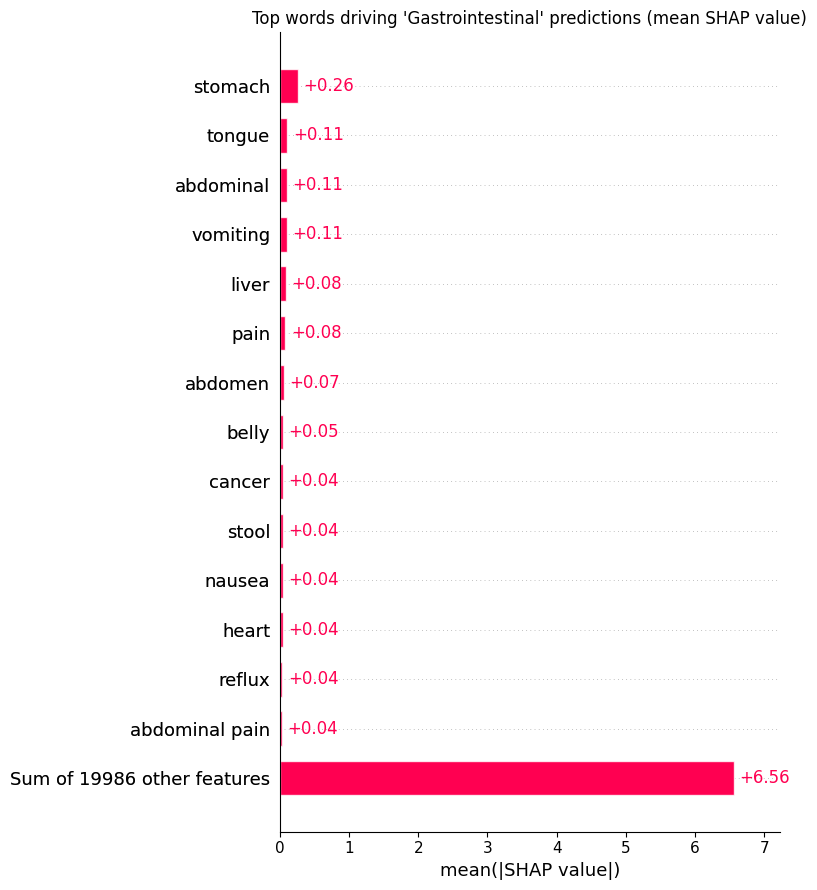

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

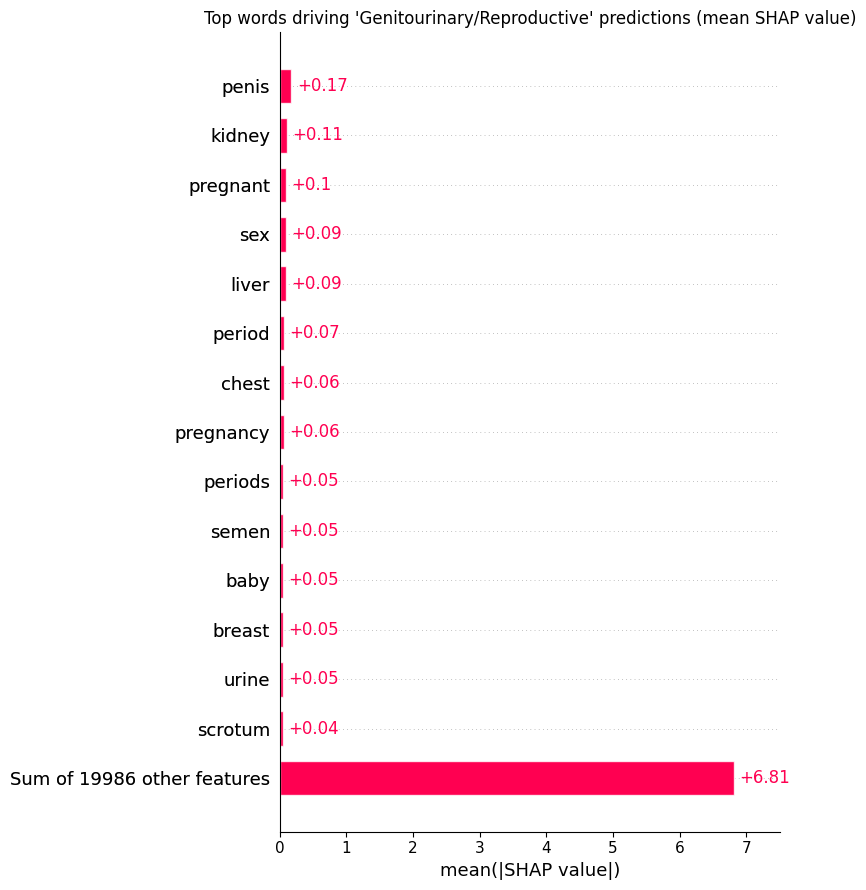

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Native SHAP plots generated and downloaded for: ['Musculoskeletal', 'Other/General', 'Gastrointestinal', 'Genitourinary/Reproductive']


In [ ]:

import shap
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

classes = list(model_combo.classes_)
feature_names = tfidf_combo.get_feature_names_out()

expected_values = explainer.expected_value
if np.isscalar(expected_values):
    expected_values = [expected_values] * len(classes)

X_sample_dense = X_sample.toarray()

REPRESENTATIVE_CLASSES = ['Musculoskeletal', 'Other/General', 'Gastrointestinal', 'Genitourinary/Reproductive']

for cls_name in REPRESENTATIVE_CLASSES:
    idx = classes.index(cls_name)

    explanation = shap.Explanation(
        values=shap_values[idx],
        base_values=np.full(X_sample_dense.shape[0], expected_values[idx]),
        data=X_sample_dense,
        feature_names=feature_names
    )

    plt.figure()
    shap.plots.bar(explanation, max_display=15, show=False)
    plt.title(f"Top words driving '{cls_name}' predictions (mean SHAP value)")
    plt.tight_layout()

    safe_name = cls_name.replace("/", "_").replace(" ", "_")
    plt.savefig(f'/content/shap_native_{safe_name}.png', dpi=150, bbox_inches='tight')
    plt.show()

    files.download(f'/content/shap_native_{safe_name}.png')

print("Native SHAP plots generated and downloaded for:", REPRESENTATIVE_CLASSES)

In [ ]:
import shap
import numpy as np

background = shap.sample(X_combo_train, 200, random_state=42)
explainer = shap.LinearExplainer(model_combo, background)

SAMPLE_SIZE = 1000
sample_idx = np.random.RandomState(42).choice(X_combo_val.shape[0], SAMPLE_SIZE, replace=False)
X_sample = X_combo_val[sample_idx]

shap_values = explainer.shap_values(X_sample)

feature_names = tfidf_combo.get_feature_names_out()
classes = list(model_combo.classes_)

if not isinstance(shap_values, list):
    shap_values = [shap_values[:, :, i] for i in range(len(classes))]

expected_values = explainer.expected_value
if np.isscalar(expected_values):
    expected_values = [expected_values] * len(classes)

X_sample_dense = X_sample.toarray()

print("SHAP objects rebuilt — ready for plotting.")

SHAP objects rebuilt — ready for plotting.


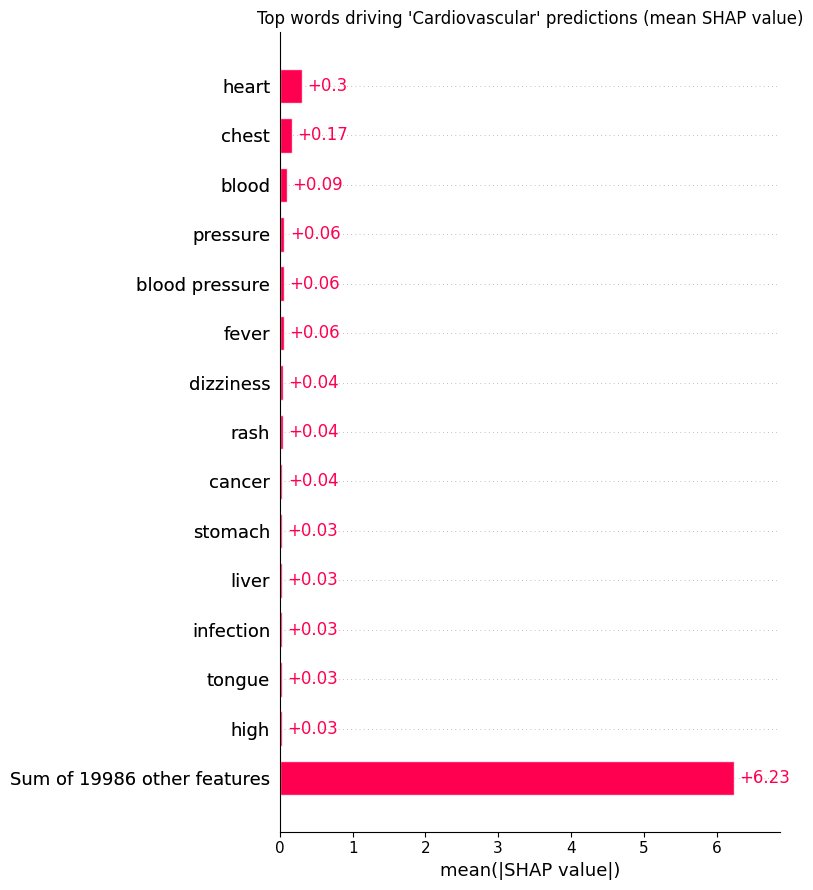

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

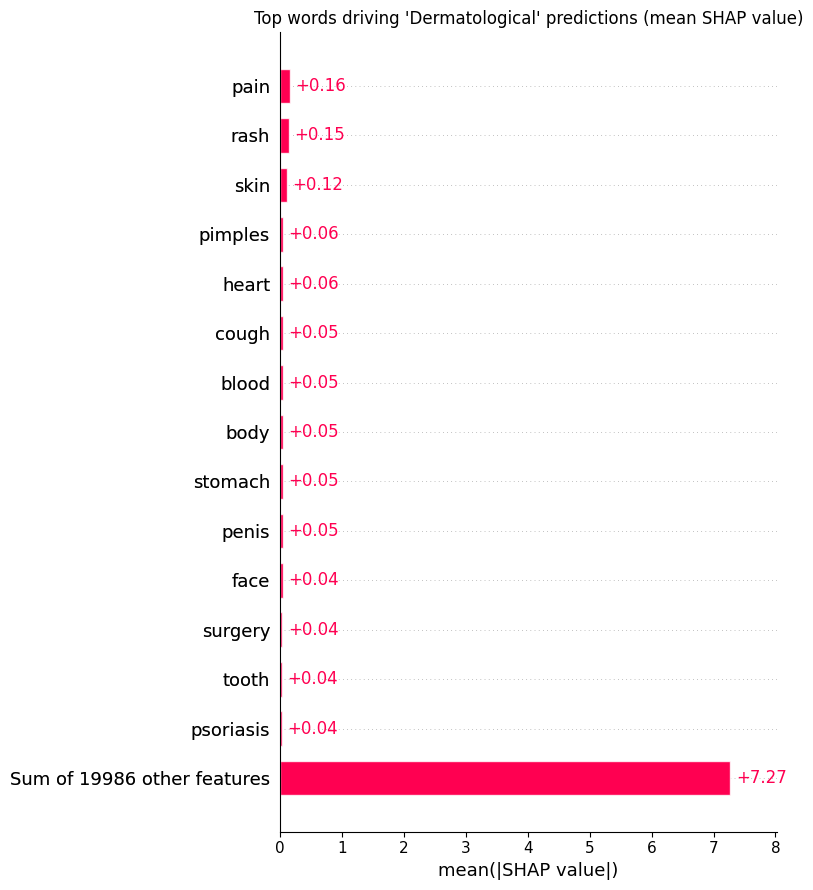

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

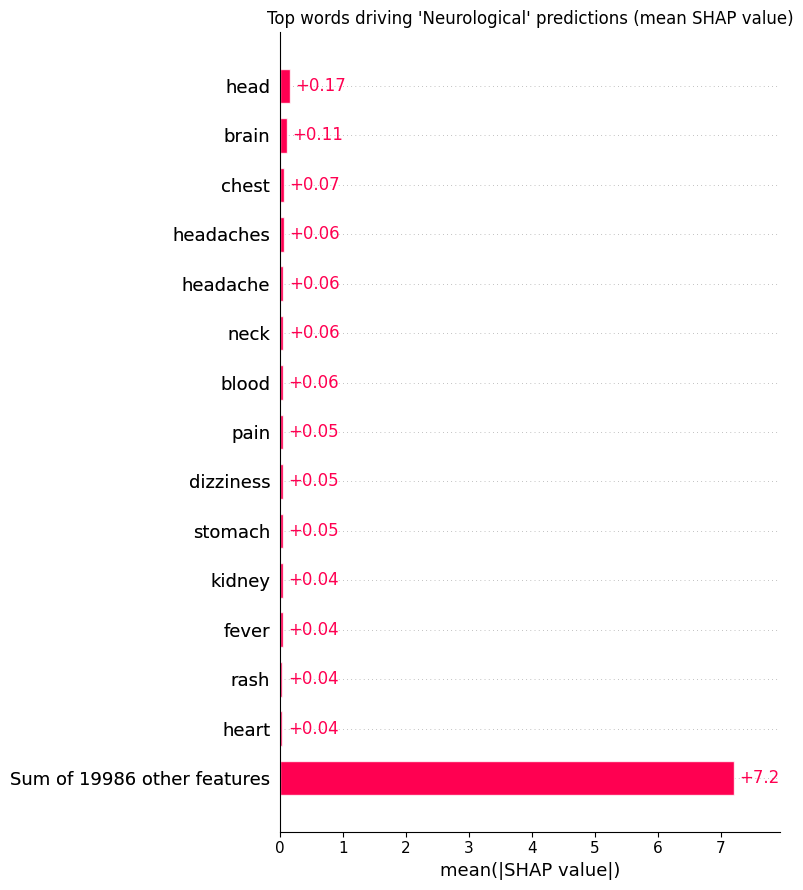

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

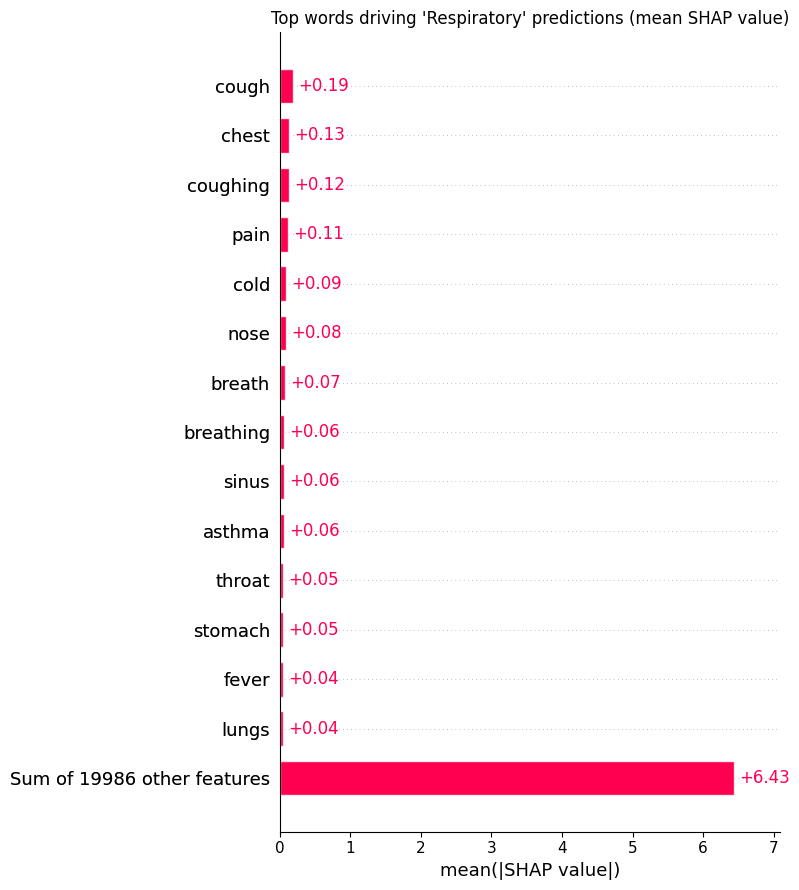

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Native SHAP plots generated and downloaded for: ['Cardiovascular', 'Dermatological', 'Neurological', 'Respiratory']


In [ ]:
import matplotlib.pyplot as plt
from google.colab import files

REMAINING_CLASSES = ['Cardiovascular', 'Dermatological', 'Neurological', 'Respiratory']

for cls_name in REMAINING_CLASSES:
    idx = classes.index(cls_name)

    explanation = shap.Explanation(
        values=shap_values[idx],
        base_values=np.full(X_sample_dense.shape[0], expected_values[idx]),
        data=X_sample_dense,
        feature_names=feature_names
    )

    plt.figure()
    shap.plots.bar(explanation, max_display=15, show=False)
    plt.title(f"Top words driving '{cls_name}' predictions (mean SHAP value)")
    plt.tight_layout()

    safe_name = cls_name.replace("/", "_").replace(" ", "_")
    plt.savefig(f'/content/shap_native_{safe_name}.png', dpi=150, bbox_inches='tight')
    plt.show()

    files.download(f'/content/shap_native_{safe_name}.png')

print("Native SHAP plots generated and downloaded for:", REMAINING_CLASSES)

# Final evaluation

In [ ]:

from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score

print("D (LogReg, boilerplate+confidence-weighted) — Validation:")
print(f"  Accuracy: {accuracy_score(y_val, pred_combo):.4f}")
print(f"  Macro F1: {f1_score(y_val, pred_combo, average='macro'):.4f}")
print(f"  Weighted F1: {f1_score(y_val, pred_combo, average='weighted'):.4f}")
print(f"  Macro Precision: {precision_score(y_val, pred_combo, average='macro'):.4f}")
print(f"  Macro Recall: {recall_score(y_val, pred_combo, average='macro'):.4f}")

print("\nG (Ensemble) — Validation:")
print(f"  Accuracy: {accuracy_score(y_val, pred_ensemble):.4f}")
print(f"  Macro F1: {f1_score(y_val, pred_ensemble, average='macro'):.4f}")
print(f"  Weighted F1: {f1_score(y_val, pred_ensemble, average='weighted'):.4f}")
print(f"  Macro Precision: {precision_score(y_val, pred_ensemble, average='macro'):.4f}")
print(f"  Macro Recall: {recall_score(y_val, pred_ensemble, average='macro'):.4f}")

X_combo_test = tfidf_combo.transform(test_df['input_nostop'])
y_test = test_df['domain_label']

proba_logreg_test = model_combo.predict_proba(X_combo_test)
proba_svm_test = svm_calibrated.predict_proba(X_combo_test)
proba_avg_test = (proba_logreg_test + proba_svm_test) / 2
pred_ensemble_test = model_combo.classes_[proba_avg_test.argmax(axis=1)]

print("\nG (Ensemble) — Test, full coverage:")
print(f"  Accuracy: {accuracy_score(y_test, pred_ensemble_test):.4f}")
print(f"  Macro F1: {f1_score(y_test, pred_ensemble_test, average='macro'):.4f}")
print(f"  Weighted F1: {f1_score(y_test, pred_ensemble_test, average='weighted'):.4f}")
print(f"  Macro Precision: {precision_score(y_test, pred_ensemble_test, average='macro'):.4f}")
print(f"  Macro Recall: {recall_score(y_test, pred_ensemble_test, average='macro'):.4f}")

D (LogReg, boilerplate+confidence-weighted) — Validation:
  Accuracy: 0.8123
  Macro F1: 0.7720
  Weighted F1: 0.8138
  Macro Precision: 0.7562
  Macro Recall: 0.7938

G (Ensemble) — Validation:
  Accuracy: 0.8194
  Macro F1: 0.7757
  Weighted F1: 0.8191
  Macro Precision: 0.7754
  Macro Recall: 0.7777

G (Ensemble) — Test, full coverage:
  Accuracy: 0.8139
  Macro F1: 0.7628
  Weighted F1: 0.8140
  Macro Precision: 0.7599
  Macro Recall: 0.7667


In [ ]:
import pandas as pd
from google.colab import files

full_comparison = pd.DataFrame([
    {'Model': 'Logistic Regression (baseline)', 'Accuracy': 0.80, 'Macro Precision': 0.73, 'Macro Recall': 0.80, 'Macro F1': 0.7541, 'Weighted F1': 0.8026},
    {'Model': 'SVM Linear (baseline)', 'Accuracy': 0.80, 'Macro Precision': 0.74, 'Macro Recall': 0.76, 'Macro F1': 0.7527, 'Weighted F1': 0.8047},
    {'Model': 'XGBoost (baseline)', 'Accuracy': 0.81, 'Macro Precision': 0.77, 'Macro Recall': 0.73, 'Macro F1': 0.7497, 'Weighted F1': 0.8071},
    {'Model': 'Random Forest', 'Accuracy': 0.76, 'Macro Precision': 0.74, 'Macro Recall': 0.68, 'Macro F1': 0.6870, 'Weighted F1': 0.7543},
    {'Model': 'Naive Bayes', 'Accuracy': 0.75, 'Macro Precision': 0.67, 'Macro Recall': 0.64, 'Macro F1': 0.6512, 'Weighted F1': 0.7433},
    {'Model': 'KNN', 'Accuracy': 0.29, 'Macro Precision': 0.66, 'Macro Recall': 0.13, 'Macro F1': 0.0709, 'Weighted F1': 0.1392},
    {'Model': 'D: LogReg tuned+refined (val)', 'Accuracy': 0.8123, 'Macro Precision': 0.7562, 'Macro Recall': 0.7938, 'Macro F1': 0.7720, 'Weighted F1': 0.8138},
    {'Model': 'G: Ensemble FINAL (val)', 'Accuracy': 0.8194, 'Macro Precision': 0.7754, 'Macro Recall': 0.7777, 'Macro F1': 0.7757, 'Weighted F1': 0.8191},
    {'Model': 'G: Ensemble — TEST (full coverage)', 'Accuracy': 0.8139, 'Macro Precision': 0.7599, 'Macro Recall': 0.7667, 'Macro F1': 0.7628, 'Weighted F1': 0.8140},
    {'Model': 'G: Ensemble — TEST @ threshold 0.7', 'Accuracy': 0.9288, 'Macro Precision': 0.8969, 'Macro Recall': 0.8950, 'Macro F1': 0.8952, 'Weighted F1': 0.9288},
]).sort_values('Macro F1', ascending=False).reset_index(drop=True)

print(full_comparison.to_string(index=False))
full_comparison.to_csv('/content/complete_metrics_table.csv', index=False)
files.download('/content/complete_metrics_table.csv')

                             Model  Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1
G: Ensemble — TEST @ threshold 0.7    0.9288           0.8969        0.8950    0.8952       0.9288
           G: Ensemble FINAL (val)    0.8194           0.7754        0.7777    0.7757       0.8191
     D: LogReg tuned+refined (val)    0.8123           0.7562        0.7938    0.7720       0.8138
G: Ensemble — TEST (full coverage)    0.8139           0.7599        0.7667    0.7628       0.8140
    Logistic Regression (baseline)    0.8000           0.7300        0.8000    0.7541       0.8026
             SVM Linear (baseline)    0.8000           0.7400        0.7600    0.7527       0.8047
                XGBoost (baseline)    0.8100           0.7700        0.7300    0.7497       0.8071
                     Random Forest    0.7600           0.7400        0.6800    0.6870       0.7543
                       Naive Bayes    0.7500           0.6700        0.6400    0.6512       0.7433
          

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

ROC-AUC (One-vs-Rest) — TEST SET, FULL COVERAGE
Macro-average AUC:    0.9756
Weighted-average AUC: 0.9742

  Cardiovascular                 AUC = 0.9848
  Dermatological                 AUC = 0.9861
  Gastrointestinal               AUC = 0.9626
  Genitourinary/Reproductive     AUC = 0.9676
  Musculoskeletal                AUC = 0.9800
  Neurological                   AUC = 0.9809
  Other/General                  AUC = 0.9631
  Respiratory                    AUC = 0.9795


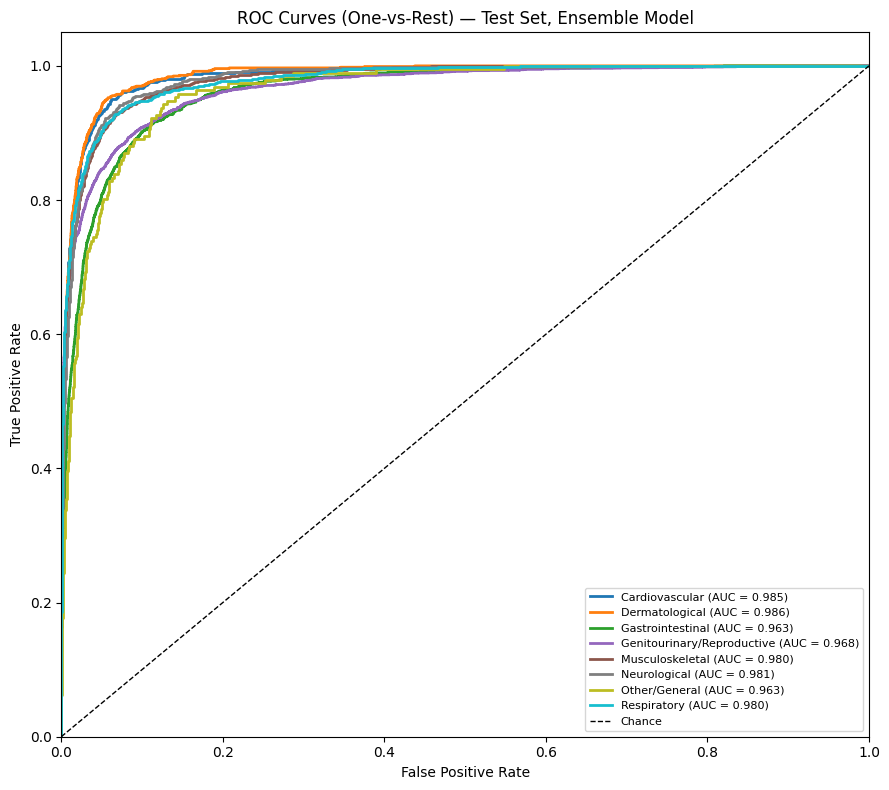


CONFUSION MATRIX — TEST SET @ THRESHOLD 0.7
                            Cardiovascular  Dermatological  Gastrointestinal  Genitourinary/Reproductive  Musculoskeletal  Neurological  Other/General  Respiratory
Cardiovascular                         842               1                 7                           8               19            10              0           17
Dermatological                           1             649                 3                           5                9             0              0            2
Gastrointestinal                        10              17              1185                          69               14             8              2           23
Genitourinary/Reproductive              18              39                81                        2520               26             7              2           12
Musculoskeletal                         13              10                13                           9             1415            24

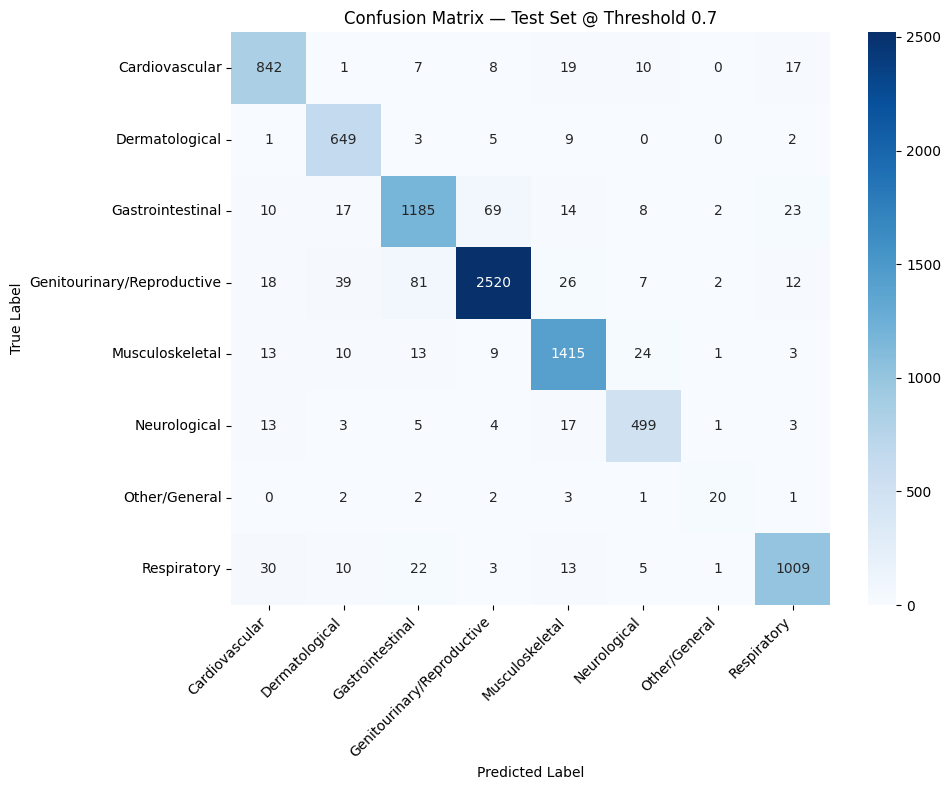

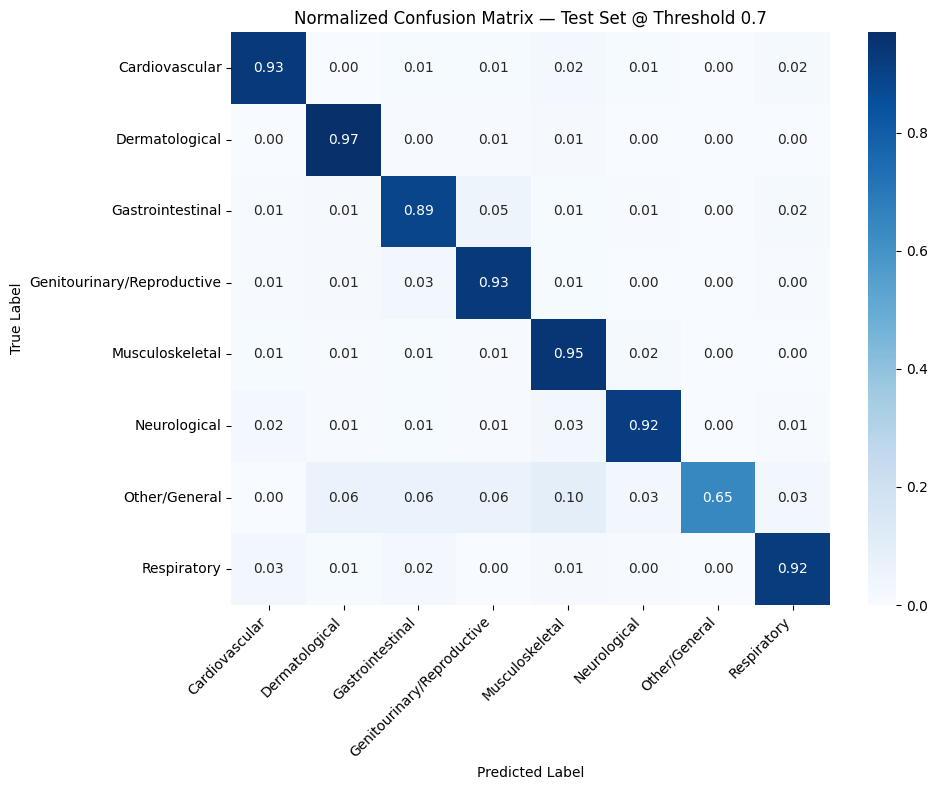

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


All ROC-AUC and confusion matrix outputs saved and downloaded.


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, roc_auc_score, confusion_matrix
from sklearn.preprocessing import label_binarize
from google.colab import files
import seaborn as sns
import pandas as pd

classes = list(model_combo.classes_)

y_test_bin = label_binarize(y_test, classes=classes)

fpr, tpr, roc_auc = {}, {}, {}
for i, cls in enumerate(classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], proba_avg_test[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

macro_auc = roc_auc_score(y_test_bin, proba_avg_test, average='macro', multi_class='ovr')
weighted_auc = roc_auc_score(y_test_bin, proba_avg_test, average='weighted', multi_class='ovr')

print("="*70)
print("ROC-AUC (One-vs-Rest) — TEST SET, FULL COVERAGE")
print("="*70)
print(f"Macro-average AUC:    {macro_auc:.4f}")
print(f"Weighted-average AUC: {weighted_auc:.4f}\n")
for i, cls in enumerate(classes):
    print(f"  {cls:30s} AUC = {roc_auc[i]:.4f}")

plt.figure(figsize=(9, 8))
colors = plt.cm.tab10(np.linspace(0, 1, len(classes)))
for i, cls in enumerate(classes):
    plt.plot(fpr[i], tpr[i], color=colors[i], lw=2,
             label=f'{cls} (AUC = {roc_auc[i]:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Chance')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves (One-vs-Rest) — Test Set, Ensemble Model')
plt.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.savefig('/content/roc_curves_test.png', dpi=150, bbox_inches='tight')
plt.show()
test_confidence = proba_avg_test.max(axis=1)

THRESHOLD = 0.7
mask_test = test_confidence >= THRESHOLD
y_test_filt = y_test[mask_test]
pred_test_filt = pred_ensemble_test[mask_test]

labels = sorted(y_test_filt.unique())
cm = confusion_matrix(y_test_filt, pred_test_filt, labels=labels)
cm_df = pd.DataFrame(cm, index=labels, columns=labels)

print("\n" + "="*70)
print(f"CONFUSION MATRIX — TEST SET @ THRESHOLD {THRESHOLD}")
print("="*70)
print(cm_df.to_string())

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title(f'Confusion Matrix — Test Set @ Threshold {THRESHOLD}')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('/content/confusion_matrix_test_threshold07.png', dpi=150, bbox_inches='tight')
plt.show()

cm_norm = confusion_matrix(y_test_filt, pred_test_filt, labels=labels, normalize='true')
plt.figure(figsize=(10, 8))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title(f'Normalized Confusion Matrix — Test Set @ Threshold {THRESHOLD}')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('/content/confusion_matrix_normalized_test_threshold07.png', dpi=150, bbox_inches='tight')
plt.show()


auc_df = pd.DataFrame([{'Class': cls, 'AUC': round(roc_auc[i], 4)} for i, cls in enumerate(classes)])
auc_df.loc[len(auc_df)] = ['Macro Average', round(macro_auc, 4)]
auc_df.loc[len(auc_df)] = ['Weighted Average', round(weighted_auc, 4)]
auc_df.to_csv('/content/roc_auc_per_class_test.csv', index=False)
cm_df.to_csv('/content/confusion_matrix_test_threshold07.csv')

for f in ['roc_curves_test.png', 'confusion_matrix_test_threshold07.png',
          'confusion_matrix_normalized_test_threshold07.png',
          'roc_auc_per_class_test.csv', 'confusion_matrix_test_threshold07.csv']:
    files.download(f'/content/{f}')

print("\nAll ROC-AUC and confusion matrix outputs saved and downloaded.")

# Confidence Tier

CONFIDENCE-TIER TRIAGE SYSTEM — TEST SET
                    Tier    N Coverage  Accuracy  Macro F1
    High (auto-classify) 7364    57.2%    0.9527    0.9018
Medium (flag for review) 3830    29.8%    0.7057    0.6911
 Low (manual assignment) 1676    13.0%    0.4511    0.4371

PER-DOMAIN TIER DISTRIBUTION (% of each true class in each tier)
tier                        High (auto-classify)  Medium (flag for review)  Low (manual assignment)
true_label                                                                                         
Cardiovascular                              60.2                      29.1                     10.7
Dermatological                              56.5                      29.0                     14.5
Gastrointestinal                            49.4                      35.7                     14.9
Genitourinary/Reproductive                  64.1                      25.7                     10.2
Musculoskeletal                             61.0         

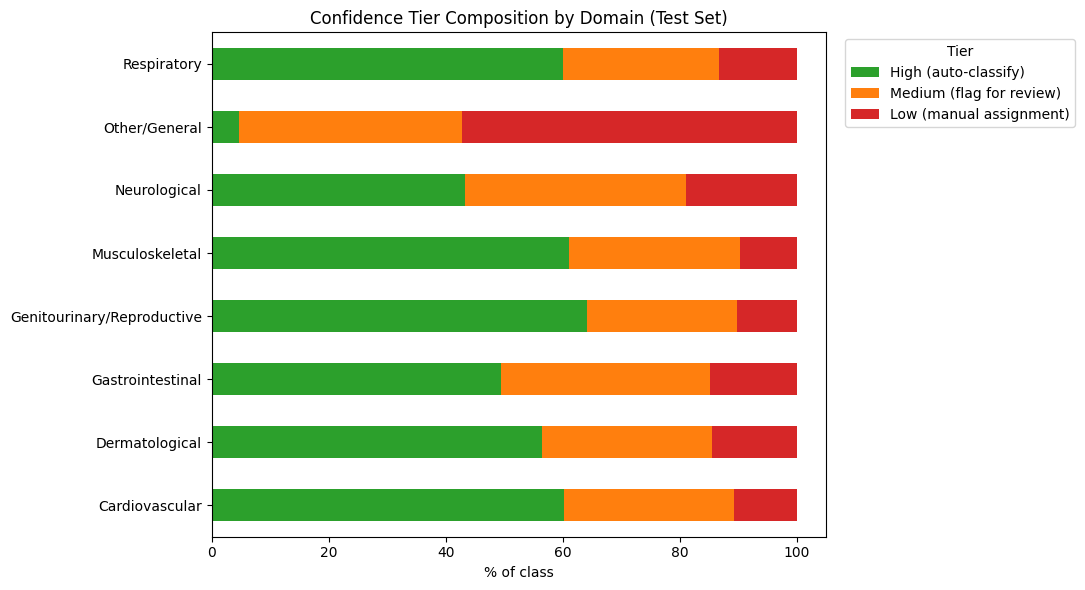

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Triage system outputs saved and downloaded.


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, classification_report
from google.colab import files

def assign_tier(conf):
    if conf >= 0.8:
        return 'High (auto-classify)'
    elif conf >= 0.5:
        return 'Medium (flag for review)'
    else:
        return 'Low (manual assignment)'

tier_labels = np.array([assign_tier(c) for c in test_confidence])

tier_df = pd.DataFrame({
    'true_label': y_test.values,
    'predicted': pred_ensemble_test,
    'confidence': test_confidence,
    'tier': tier_labels
})

tier_order = ['High (auto-classify)', 'Medium (flag for review)', 'Low (manual assignment)']
summary_rows = []

for tier in tier_order:
    subset = tier_df[tier_df['tier'] == tier]
    coverage = len(subset) / len(tier_df)
    acc = accuracy_score(subset['true_label'], subset['predicted'])
    macro_f1 = f1_score(subset['true_label'], subset['predicted'], average='macro', zero_division=0)
    summary_rows.append({
        'Tier': tier,
        'N': len(subset),
        'Coverage': f"{coverage*100:.1f}%",
        'Accuracy': round(acc, 4),
        'Macro F1': round(macro_f1, 4)
    })

tier_summary = pd.DataFrame(summary_rows)
print("="*70)
print("CONFIDENCE-TIER TRIAGE SYSTEM — TEST SET")
print("="*70)
print(tier_summary.to_string(index=False))

print("\n" + "="*70)
print("PER-DOMAIN TIER DISTRIBUTION (% of each true class in each tier)")
print("="*70)
domain_tier_dist = pd.crosstab(tier_df['true_label'], tier_df['tier'], normalize='index') * 100
domain_tier_dist = domain_tier_dist[tier_order].round(1)
print(domain_tier_dist.to_string())

fig, ax = plt.subplots(figsize=(11, 6))
domain_tier_dist.plot(kind='barh', stacked=True, ax=ax,
                       color=['#2ca02c', '#ff7f0e', '#d62728'])
ax.set_xlabel('% of class')
ax.set_ylabel('')
ax.set_title('Confidence Tier Composition by Domain (Test Set)')
ax.legend(title='Tier', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('/content/confidence_tier_by_domain.png', dpi=150, bbox_inches='tight')
plt.show()

tier_summary.to_csv('/content/confidence_tier_summary.csv', index=False)
domain_tier_dist.to_csv('/content/confidence_tier_by_domain.csv')
tier_df.to_csv('/content/full_tier_assignments_test.csv', index=False)

for f in ['confidence_tier_summary.csv', 'confidence_tier_by_domain.csv',
          'full_tier_assignments_test.csv', 'confidence_tier_by_domain.png']:
    files.download(f'/content/{f}')

print("\nTriage system outputs saved and downloaded.")

SHAP SIGNAL CONCENTRATION BY CONFIDENCE TIER
(top1_concentration = how much of the total SHAP signal comes from
 the single most influential word — higher = more concentrated)
                            mean  median     std
tier                                            
High (auto-classify)      0.1779  0.1603  0.0736
Medium (flag for review)  0.1712  0.1524  0.0726
Low (manual assignment)   0.1188  0.1061  0.0640


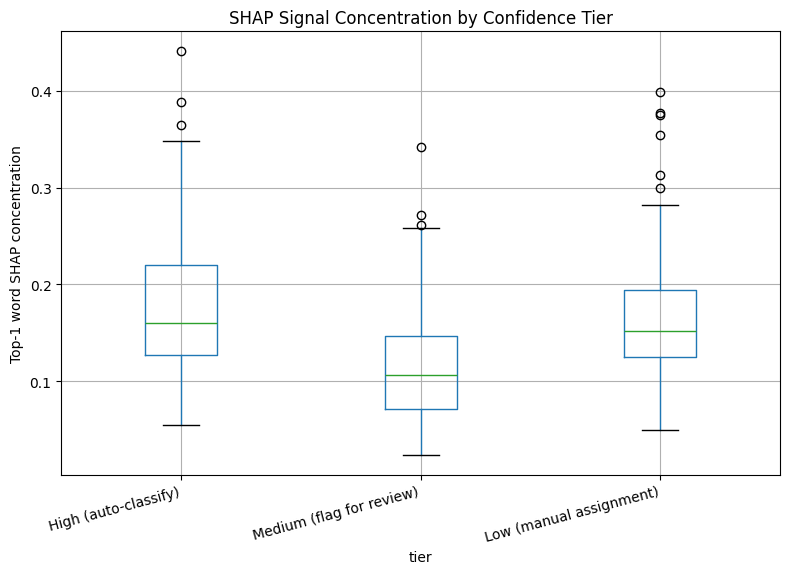

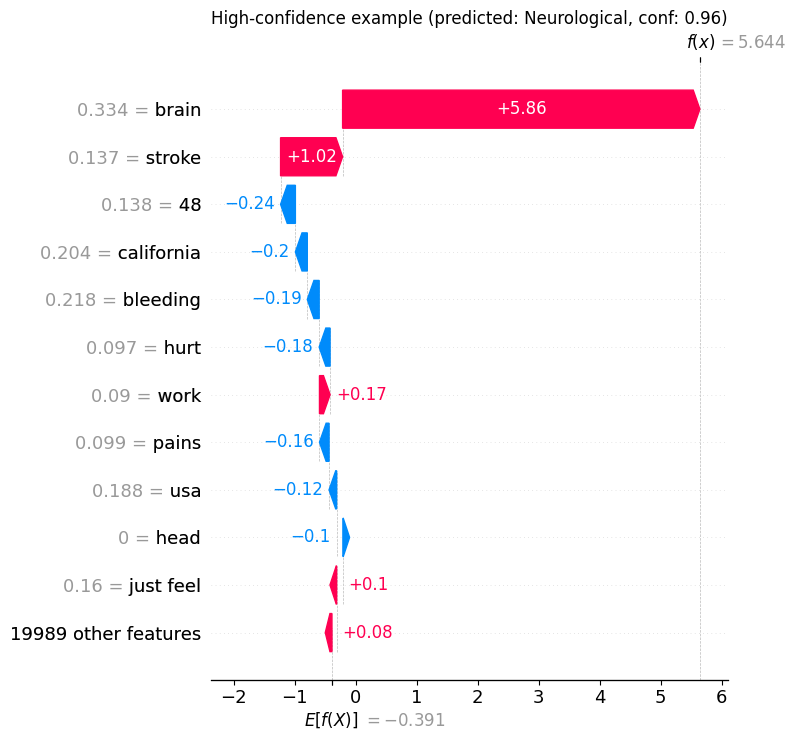

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

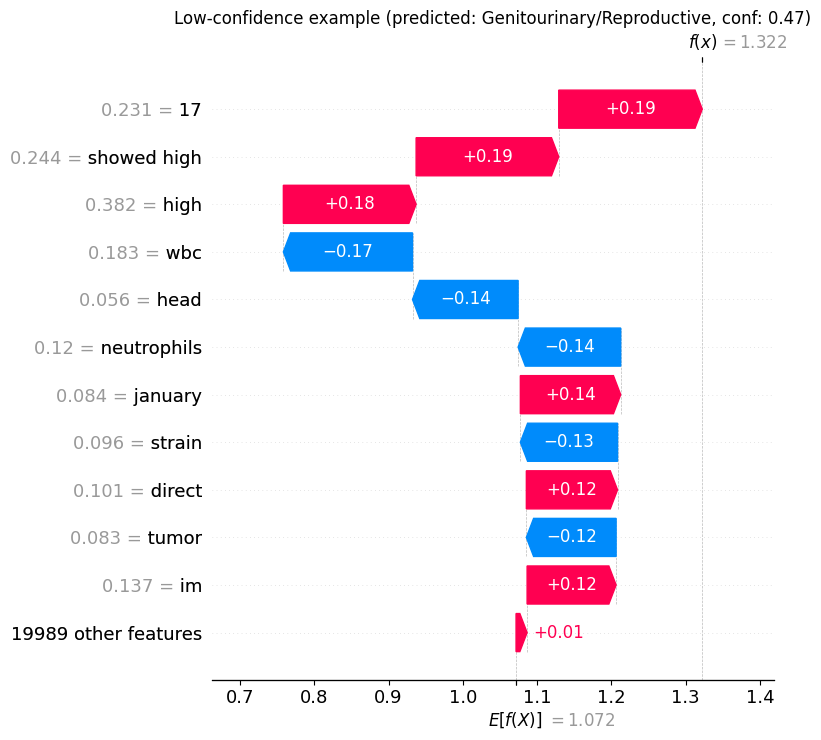

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


SHAP tier analysis complete and downloaded.


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from google.colab import files

tier_df_reset = tier_df.reset_index(drop=True)
SAMPLE_PER_TIER = 100

sampled_idx = []
for tier in tier_order:
    tier_idx = tier_df_reset[tier_df_reset['tier'] == tier].index.tolist()
    n = min(SAMPLE_PER_TIER, len(tier_idx))
    sampled_idx.extend(np.random.RandomState(42).choice(tier_idx, n, replace=False))

sampled_idx = np.array(sampled_idx)
X_tier_sample = X_combo_test[sampled_idx]

shap_values_test = explainer.shap_values(X_tier_sample)
classes = list(model_combo.classes_)
if not isinstance(shap_values_test, list):
    shap_values_test = [shap_values_test[:, :, i] for i in range(len(classes))]

concentration_scores = []
predicted_classes_sample = pred_ensemble_test[sampled_idx]

for row_i, global_i in enumerate(sampled_idx):
    cls_idx = classes.index(predicted_classes_sample[row_i])
    row_shap = np.abs(shap_values_test[cls_idx][row_i])
    total = row_shap.sum()
    top1 = row_shap.max()
    concentration = top1 / total if total > 0 else 0
    concentration_scores.append(concentration)

tier_analysis = pd.DataFrame({
    'tier': tier_df_reset.loc[sampled_idx, 'tier'].values,
    'confidence': tier_df_reset.loc[sampled_idx, 'confidence'].values,
    'top1_concentration': concentration_scores
})

print("="*70)
print("SHAP SIGNAL CONCENTRATION BY CONFIDENCE TIER")
print("(top1_concentration = how much of the total SHAP signal comes from")
print(" the single most influential word — higher = more concentrated)")
print("="*70)
print(tier_analysis.groupby('tier')['top1_concentration'].agg(['mean', 'median', 'std']).reindex(tier_order).round(4))

fig, ax = plt.subplots(figsize=(8, 6))
tier_analysis.boxplot(column='top1_concentration', by='tier', ax=ax,
                       positions=range(len(tier_order)))
ax.set_xticklabels(tier_order, rotation=15, ha='right')
ax.set_ylabel('Top-1 word SHAP concentration')
ax.set_title('SHAP Signal Concentration by Confidence Tier')
plt.suptitle('')
plt.tight_layout()
plt.savefig('/content/shap_concentration_by_tier.png', dpi=150, bbox_inches='tight')
plt.show()

feature_names = tfidf_combo.get_feature_names_out()
X_tier_sample_dense = X_tier_sample.toarray()
expected_values = explainer.expected_value
if np.isscalar(expected_values):
    expected_values = [expected_values] * len(classes)

example_rows = {
    'High-confidence example': tier_analysis[tier_analysis['tier'] == tier_order[0]]['top1_concentration'].idxmax(),
    'Low-confidence example': tier_analysis[tier_analysis['tier'] == tier_order[2]]['top1_concentration'].idxmin()
}

for label, row_pos in example_rows.items():
    cls_idx = classes.index(predicted_classes_sample[row_pos])
    explanation = shap.Explanation(
        values=shap_values_test[cls_idx][row_pos],
        base_values=expected_values[cls_idx],
        data=X_tier_sample_dense[row_pos],
        feature_names=feature_names
    )
    plt.figure()
    shap.plots.waterfall(explanation, max_display=12, show=False)
    plt.title(f"{label} (predicted: {predicted_classes_sample[row_pos]}, "
              f"conf: {tier_analysis.loc[row_pos, 'confidence']:.2f})")
    plt.tight_layout()
    safe_label = label.replace(" ", "_")
    plt.savefig(f'/content/shap_case_study_{safe_label}.png', dpi=150, bbox_inches='tight')
    plt.show()
    files.download(f'/content/shap_case_study_{safe_label}.png')

tier_analysis.to_csv('/content/shap_concentration_by_tier.csv', index=False)
files.download('/content/shap_concentration_by_tier.csv')
files.download('/content/shap_concentration_by_tier.png')

print("\nSHAP tier analysis complete and downloaded.")